In [2]:
import numpy as np

def accel_threshold_filter(data, timestamps, accel_thresh):
    data = np.asarray(data)
    timestamps = np.asarray(timestamps)

    # Case 1: 1D input (single velocity trace)
    if data.ndim == 1:
        filtered = data.copy()
        last_accel = 0.0
        for i in range(1, len(data)):
            dt = timestamps[i] - timestamps[i-1]
            if dt <= 0:
                continue
            accel = (data[i] - filtered[i-1]) / dt
            if abs(accel) > accel_thresh:
                accel = last_accel
                filtered[i] = filtered[i-1] + accel * dt
            else:
                filtered[i] = data[i]
                last_accel = accel
        return filtered

    # Case 2: 2D input (channels × T)
    filtered = data.copy()
    for ch in range(data.shape[0]):
        last_accel = 0.0
        for i in range(1, data.shape[1]):
            dt = timestamps[i] - timestamps[i-1]
            if dt <= 0:
                continue
            accel = (data[ch, i] - filtered[ch, i-1]) / dt
            if abs(accel) > accel_thresh:
                accel = last_accel
                filtered[ch, i] = filtered[ch, i-1] + accel * dt
            else:
                filtered[ch, i] = data[ch, i]
                last_accel = accel
    return filtered


In [3]:
import numpy as np

def exp_moving_average(data, alpha):

#Applies an exponentially decaying moving average filter to a 1D NumPy array.

    if len(data) == 0:
        return data

    smoothed = np.empty_like(data, dtype=float)
    smoothed[0] = data[0]  # Initialize with the first data point.
    for i in range(1, len(data)):
        smoothed[i] = alpha * data[i] + (1 - alpha) * smoothed[i-1]
    return smoothed

# For multidimensional data
def exp_mov_ave_2d(data, alpha):
   # Apply the 1D filter to each row.
    smoothed = np.array([exp_moving_average(channel, alpha) for channel in data])
    return smoothed


In [4]:
def savgol_filter_1d(y: np.ndarray, window_size: int, polyorder: int) -> np.ndarray:
    """
    Pure‑NumPy Savitzky–Golay smoothing.
    y            – 1D data array
    window_size  – odd integer >= polyorder+2
    polyorder    – polynomial order < window_size
    """
    
    # sanity checks
    if window_size % 2 == 0 or window_size <= polyorder:
        raise ValueError("window_size must be odd and > polyorder")
    half = window_size // 2

    # build the Vandermonde matrix for (-half ... +half)
    # A[i,j] = (i - half)**j
    x = np.arange(-half, half+1, dtype=float)
    A = np.vander(x, polyorder+1, increasing=True)  # shape (window, poly+1)

    # compute the pseudoinverse and take the first row = smoothing coefficients
    ATA = A.T @ A
    pinv = np.linalg.pinv(ATA) @ A.T
    coeffs = pinv[0]   # apply to y to get smoothed value at center

    # pad the signal at the edges by repeating end‑values
    y_padded = np.pad(y, (half, half), mode='edge')

    # convolve and return only the “valid” part
    return np.convolve(y_padded, coeffs[::-1], mode='valid')

In [5]:
def encoder_to_velocity(encoder_counts, timestamps, ppr=1539):
    """
    Convert raw encoder counts into angular velocities for each wheel.

    Args:
        encoder_counts: ndarray of shape (4, T) or (T, 4) — counts for [fr, br, fl, bl]
        timestamps: ndarray of shape (T,) — timestamps

    Returns:
        vel: ndarray of shape (4, T) — linear velocities in m/s
    """
    if encoder_counts.shape[0] == 4:
        encoder_counts = encoder_counts.T  # shape (T, 4)

    window, order = 11, 5
    enc = encoder_counts  # (T, 4)

    # # Apply Savitzky–Golay smoothing per wheel
    # enc_smooth = np.vstack([
    #     savgol_filter_1d(enc[:, i], window, order)
    #     for i in range(enc.shape[1])
    # ]).T  # shape (T, 4)

    # CPR = Counts per revolution
    cpr = ppr * 4

    # Convert counts to radians
    angles = (enc - enc[0]) / cpr * 2 * np.pi
    angles_unwrapped = np.unwrap(angles, axis=0)

    # Time difference
    dt = np.diff(timestamps)
    dtheta = np.diff(angles_unwrapped, axis=0)
    ang_vel = dtheta / dt[:, None]
    ang_vel = np.vstack((np.zeros((1, 4)), ang_vel))  # align shape (T, 4)

    wheel_radius = 0.127
    vel = ang_vel * wheel_radius  # (T, 4)

    # Spike removal (clip outliers > 1 m/s)
    for w in range(vel.shape[1]):
        col = vel[:, w]
        mask = np.abs(col) > 1.0
        bad_idxs = np.flatnonzero(mask)
        for i in bad_idxs:
            if i > 0:
                col[i] = col[i-1]

    return vel

In [6]:
def despike_velocity(t, v, vmax=1.5, amax=20.0):
    """
    Remove impossible velocity spikes.
    Bad samples are replaced by linear interpolation from neighboring good samples.

    vmax: absolute velocity limit [m/s]
    amax: acceleration jump limit [m/s^2]
    """

    t = np.asarray(t, dtype=float)
    v = np.asarray(v, dtype=float)

    v_clean = v.copy()

    bad = ~np.isfinite(v_clean)

    # Impossible velocity magnitude
    bad |= np.abs(v_clean) > vmax

    # Impossible acceleration jump
    dv = np.diff(v_clean)
    dt = np.diff(t)

    acc = np.zeros_like(dv)
    valid_dt = dt > 1e-6
    acc[valid_dt] = dv[valid_dt] / dt[valid_dt]

    bad[1:] |= np.abs(acc) > amax

    good = ~bad

    if np.sum(good) < 2:
        print("Warning: too few good samples after despiking")
        return v_clean

    v_clean[bad] = np.interp(t[bad], t[good], v_clean[good])

    return v_clean

In [10]:
import numpy as np

def segment_welch_psd(t_seg, x_seg, nperseg=256, noverlap=128, window="hann", detrend=True):
    """
    Welch PSD for a single segment (no SciPy).
    Inputs:
      t_seg: (N,) seconds (nonuniform ok; uses median dt)
      x_seg: (N,) signal
      nperseg/noverlap: Welch params
      window: 'hann' or 'boxcar'
      detrend: remove mean before PSD

    Returns:
      f: (K,) frequency in Hz
      Pxx: (K,) PSD in units^2/Hz
    """
    t = np.asarray(t_seg, dtype=float)
    x = np.asarray(x_seg, dtype=float)

    if t.size != x.size or t.size < 8:
        return np.array([]), np.array([])

    dt = np.diff(t)
    dt = dt[dt > 0]
    if dt.size == 0:
        return np.array([]), np.array([])
    fs = 1.0 / np.median(dt)

    if detrend:
        x = x - np.mean(x)

    N = x.size
    nperseg = int(min(nperseg, N))
    if nperseg < 8:
        return np.array([]), np.array([])

    noverlap = int(min(noverlap, nperseg - 1))
    step = nperseg - noverlap
    if step <= 0:
        return np.array([]), np.array([])

    if window == "hann":
        w = np.hanning(nperseg)
    else:
        w = np.ones(nperseg)

    U = np.sum(w**2)  # window power normalization

    # choose nfft as next power of 2 >= nperseg
    nfft = 1 << int(np.ceil(np.log2(nperseg)))
    f = np.fft.rfftfreq(nfft, d=1.0/fs)

    starts = np.arange(0, N - nperseg + 1, step, dtype=int)
    if starts.size == 0:
        return np.array([]), np.array([])

    P_accum = np.zeros(f.size, dtype=float)
    for s in starts:
        seg = x[s:s+nperseg] * w
        X = np.fft.rfft(seg, n=nfft)
        P = (np.abs(X)**2) / (fs * U)  # periodogram scaling
        P_accum += P

    Pxx = P_accum / starts.size
    return f, Pxx


def segment_fft_spectrum(t_seg, x_seg, window="hann", detrend=True):
    """
    Single-segment FFT magnitude spectrum (no averaging).
    Inputs:
      t_seg: (N,) seconds (nonuniform ok; uses median dt)
      x_seg: (N,) signal
      window: 'hann' or 'boxcar'
      detrend: remove mean before FFT

    Returns:
      f: (K,) frequency in Hz
      mag: (K,) magnitude (same units as x)
    """
    t = np.asarray(t_seg, dtype=float)
    x = np.asarray(x_seg, dtype=float)

    if t.size != x.size or t.size < 4:
        return np.array([]), np.array([])

    dt = np.diff(t)
    dt = dt[dt > 0]
    if dt.size == 0:
        return np.array([]), np.array([])
    fs = 1.0 / np.median(dt)

    if detrend:
        x = x - np.mean(x)

    N = x.size
    if window == "hann":
        w = np.hanning(N)
    else:
        w = np.ones(N)

    xw = x * w

    # FFT length: next power of 2 for nicer frequency grid
    nfft = 1 << int(np.ceil(np.log2(N)))
    X = np.fft.rfft(xw, n=nfft)
    f = np.fft.rfftfreq(nfft, d=1.0/fs)

    mag = np.abs(X)
    return f, mag

def spectral_entropy_from_psd(Pxx, eps=1e-12):
    """
    Spectral entropy in [0,1] from a PSD array.
    Lower = concentrated spectrum, Higher = flatter/more 'noisy'.
    """
    Pxx = np.asarray(Pxx, dtype=float)
    if Pxx.size == 0 or not np.all(np.isfinite(Pxx)):
        return np.nan
    p = Pxx + eps
    p = p / np.sum(p)
    H = -np.sum(p * np.log(p))
    return float(H / np.log(p.size))


def dominant_frequency(f, Pxx, fmin=0.0, fmax=None):
    """
    Frequency (Hz) at which PSD is maximal within [fmin, fmax].
    """
    f = np.asarray(f, dtype=float)
    Pxx = np.asarray(Pxx, dtype=float)
    if f.size == 0 or Pxx.size == 0:
        return np.nan

    mask = f >= float(fmin)
    if fmax is not None:
        mask &= (f <= float(fmax))

    if not np.any(mask):
        return np.nan

    idx = np.argmax(Pxx[mask])
    return float(f[mask][idx])


def bandpower_from_psd(f, Pxx, f_lo, f_hi):
    """
    Integrate PSD over frequency band [f_lo, f_hi] using trapezoid rule.
    Units: (signal^2) since PSD (signal^2/Hz) integrated over Hz.
    """
    f = np.asarray(f, dtype=float)
    Pxx = np.asarray(Pxx, dtype=float)
    if f.size == 0 or Pxx.size == 0:
        return np.nan

    f_lo = float(f_lo)
    f_hi = float(f_hi)
    if f_hi <= f_lo:
        return np.nan

    mask = (f >= f_lo) & (f <= f_hi)
    if np.sum(mask) < 2:
        return 0.0

    return float(np.trapezoid(Pxx[mask], f[mask]))


def bandpower_ratios(f, Pxx, bands=((0.0, 2.0), (2.0, 10.0), (10.0, None)), fmax=None):
    """
    Convenience: return bandpowers and ratios to total power.
    Default bands: [0-2], [2-10], [10-inf] Hz.
    If fmax is provided, total power is computed up to fmax.
    Returns:
      bp: dict of bandpower
      br: dict of bandpower_ratio (band / total)
    """
    f = np.asarray(f, dtype=float)
    Pxx = np.asarray(Pxx, dtype=float)
    if f.size == 0 or Pxx.size == 0:
        return {}, {}

    if fmax is None:
        total = float(np.trapezoid(Pxx, f))
    else:
        mask_total = f <= float(fmax)
        if np.sum(mask_total) < 2:
            total = np.nan
        else:
            total = float(np.trapezoid(Pxx[mask_total], f[mask_total]))

    bp = {}
    br = {}
    for (lo, hi) in bands:
        lo = float(lo)
        if hi is None:
            hi_val = float(f.max()) if fmax is None else float(fmax)
        else:
            hi_val = float(hi)
        key = f"{lo:g}-{hi_val:g}Hz"
        p = bandpower_from_psd(f, Pxx, lo, hi_val)
        bp[key] = p
        br[key] = (p / total) if (np.isfinite(total) and total > 0) else np.nan

    return bp, br

def crop_by_time(t, t0, t1):
    t = np.asarray(t, dtype=float)
    return (t >= t0) & (t <= t1)

num_imu (3, 6456)
Odom twists shape: (6, 1317)
Encoder counts: [[ 80960.  80960.  80960. ...  77634.  77634.  77634.]
 [-51408. -51408. -51408. ... -64747. -64747. -64747.]
 [ 82936.  82936.  82936. ...  75772.  75772.  75772.]
 [103829. 103829. 103829. ...  97754.  97754.  97754.]]
Encoder timestamps: [1.76971439e+09 1.76971439e+09 1.76971439e+09 1.76971439e+09
 1.76971439e+09]
First 10 odom twists [[ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e

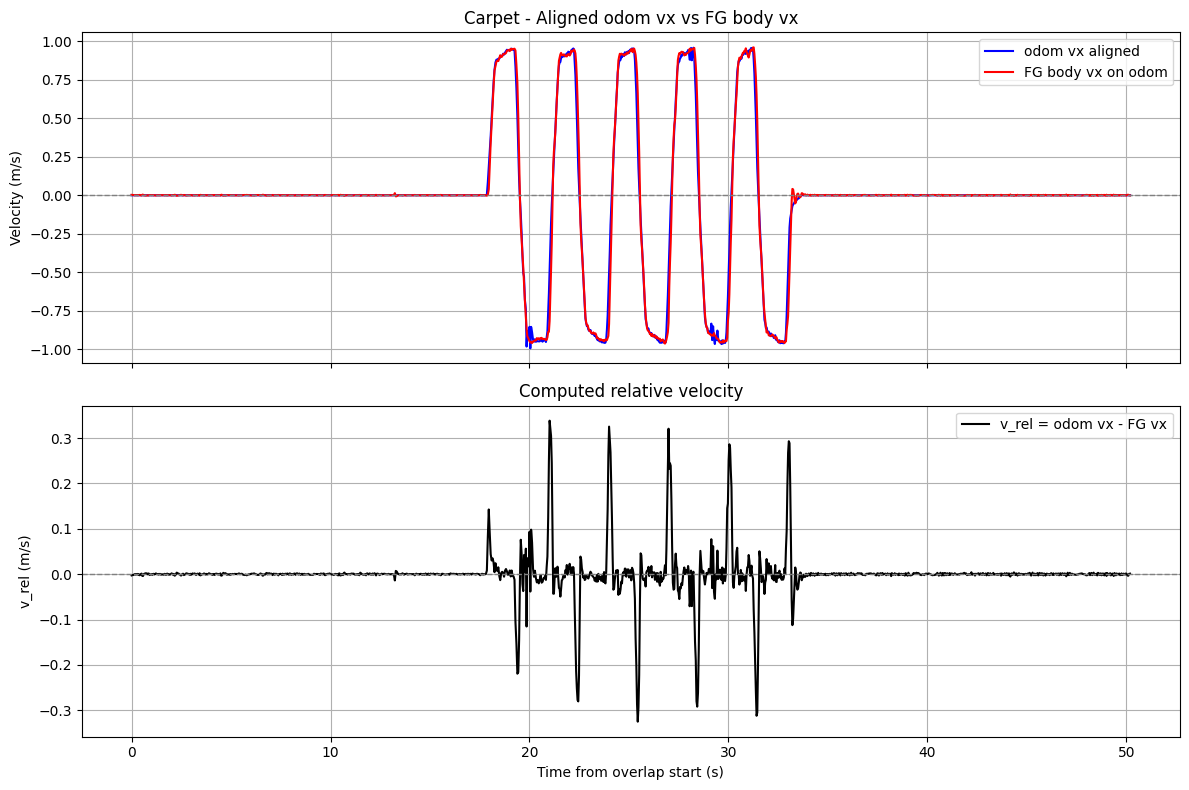


--- Alignment diagnostics ---
corr(odom, FG): 0.9930634394635722
corr(odom, -FG): -0.9930634394635722
mean odom - FG: 0.0006561237871341394
mean odom + FG: -0.040690870177463326


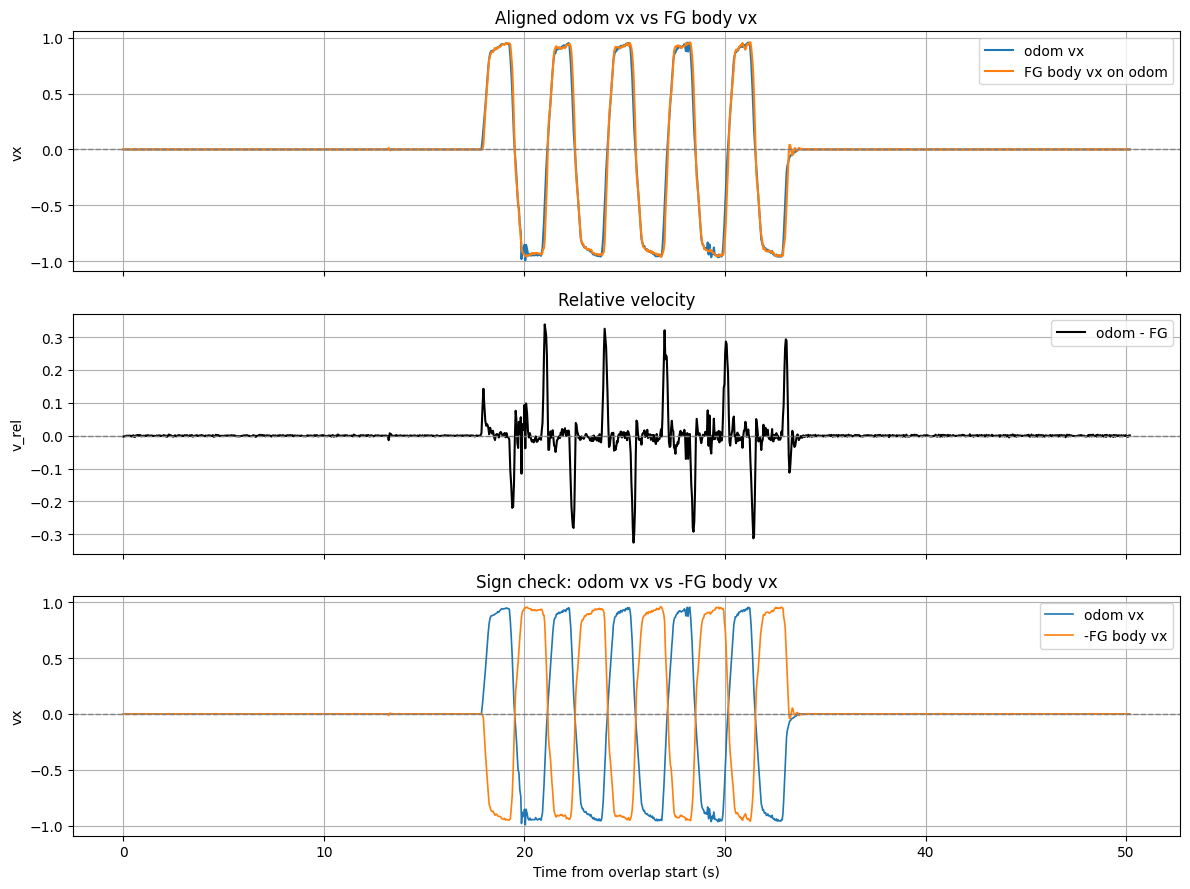

Computed relative velocity using aligned FG + odom.
FG time: 1769714386.5221994 to 1769714436.7222254 N = 5028
Odom time: 1769714386.4879973 to 1769714436.7205715 N = 1317
Overlap: 1769714386.5221994 to 1769714436.7205715 duration = 50.19837212562561
v_rel shape: (1315,)
FG span: 1769714386.5221994 1769714436.7222254 duration 50.20002603530884 len 5028
Odom span: 1769714386.4879973 1769714436.7205715 duration 50.232574224472046 len 1317
Overlap seconds: 50.19837212562561
FG monotonic: True
Encoder velocities: [[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


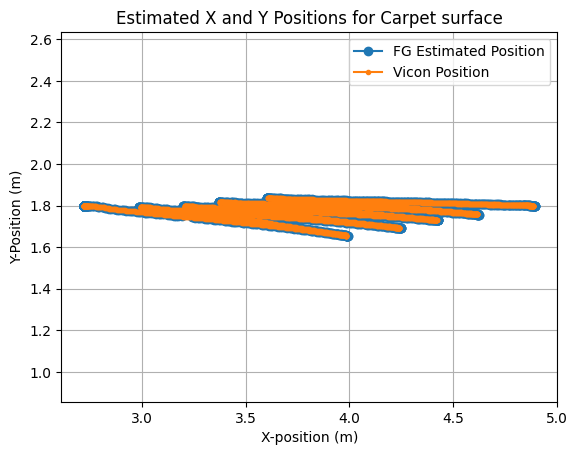


Position error vs Vicon
-----------------------
RMS position error:  0.0020 m
Mean position error: 0.0009 m
Max position error:  0.0093 m


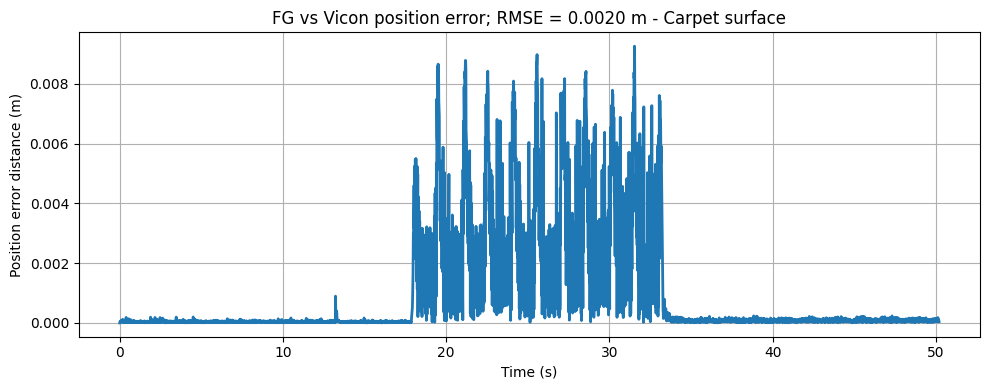


FG velocity vs odom velocity
----------------------------
RMSE velocity error: 0.0524 m/s
MAE velocity error:  0.0165 m/s


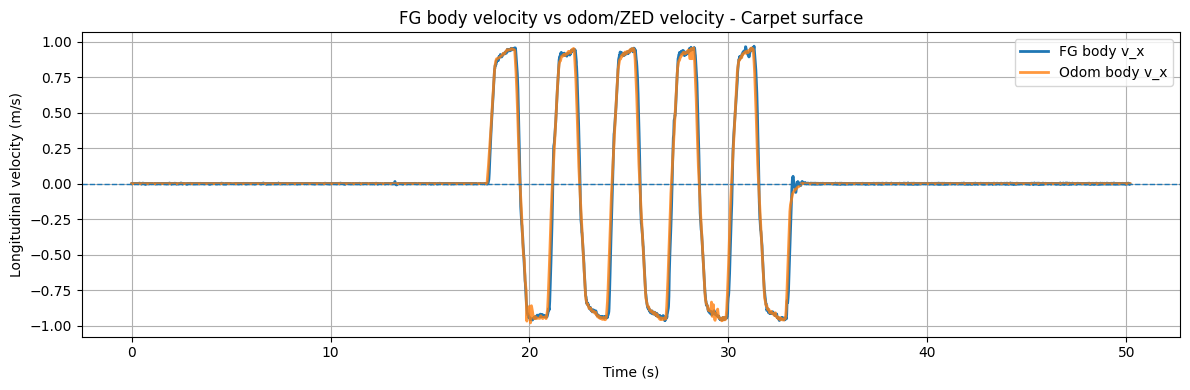

Persistent positive-slope segments: 5
Persistent negative-slope segments: 5
  seg 0: kept, duration=0.384s, fs=20.76 Hz
  seg 1: kept, duration=0.540s, fs=27.84 Hz
  seg 2: kept, duration=0.576s, fs=27.80 Hz
  seg 3: kept, duration=0.576s, fs=27.80 Hz
  seg 4: kept, duration=0.576s, fs=27.85 Hz
  seg 0: kept, duration=0.645s, fs=23.73 Hz
  seg 1: kept, duration=0.540s, fs=27.83 Hz
  seg 2: kept, duration=0.540s, fs=27.78 Hz
  seg 3: kept, duration=0.537s, fs=25.66 Hz
  seg 4: kept, duration=0.540s, fs=27.84 Hz
Positive-slope spectral segments used: 5
Negative-slope spectral segments used: 5

Positive-slope segments
Detected: 5
Durations: [0.384 0.54  0.576 0.576 0.576]
0.30–0.50 s: 1
At least 0.50 s: 4
Median duration: 0.576162576675415

Negative-slope segments
Detected: 5
Durations: [0.645 0.54  0.54  0.537 0.54 ]
0.30–0.50 s: 0
At least 0.50 s: 5
Median duration: 0.5403704643249512
Appended smoothed stats for Carpet → Surface_spectral_analysis.npz


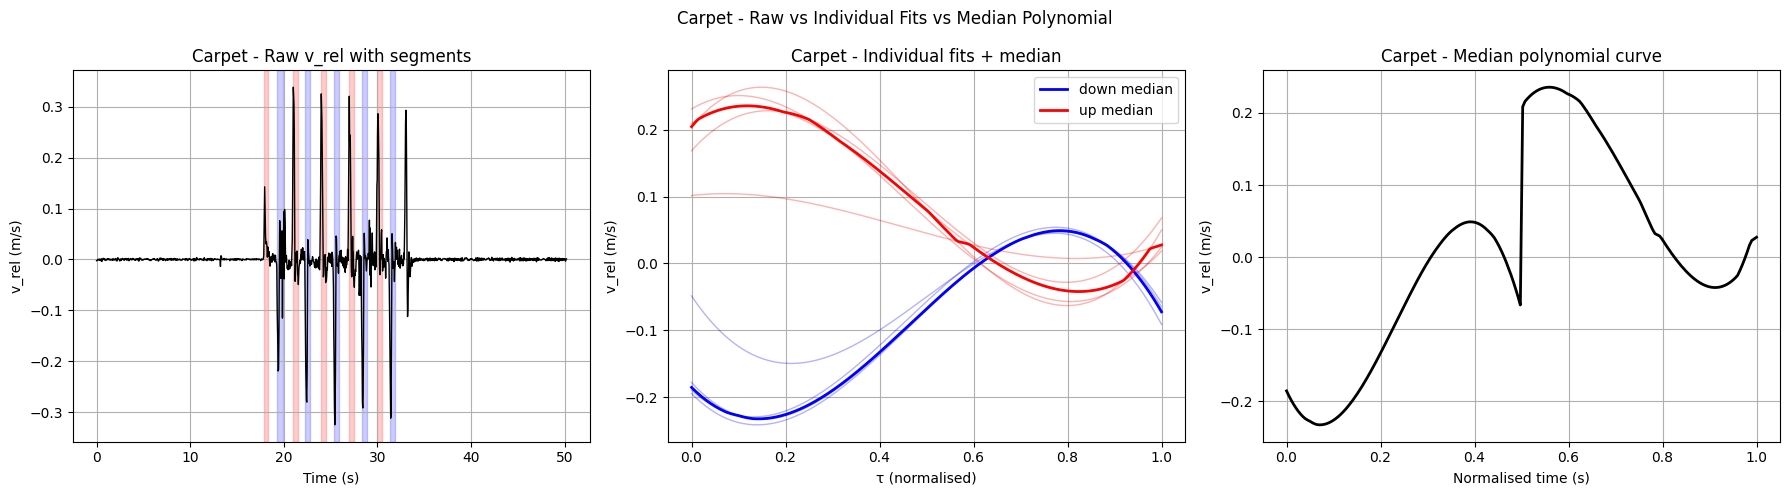

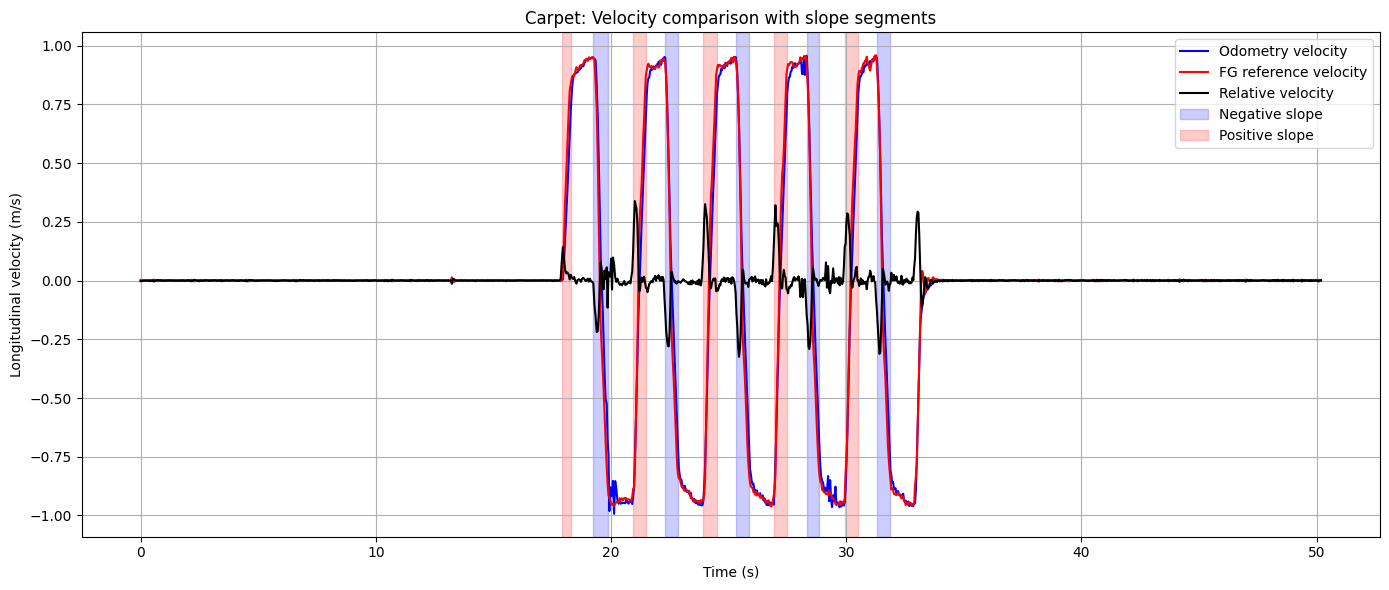

In [ ]:
import rclpy
from rclpy.node import Node
import numpy as np
import gtsam
from gtsam.symbol_shorthand import X, V, B  # Pose, Velocity, and Bias keys
import matplotlib.pyplot as plt
import math
import os

   
class FactorGraphEstimator(Node):
    def __init__(self):
        super().__init__('factor_graph_estimator')

        # Load sensor data and downsample Vicon
        data = np.load("../Sensor_data/2026_1_29__14_19_44Carpet_0.npz")
        pred_rv = np.load("predicted_rv.npz", allow_pickle=True)
        v_rel_pred = pred_rv["v_rel_pred"].item()
        v_rel_time = pred_rv["v_rel_time"].item()
        v_odom_motion = pred_rv["v_odom_motion"].item()
        sample_idx_motion = pred_rv["sample_idx_motion"].item()
        self.category = "Carpet"
        self.imu_acc = data["imu_acc"]          # (3, num_imu)
        print("num_imu",np.shape(self.imu_acc))
        self.imu_gyr = data["imu_gyro"]         # (3, num_imu)
        self.imu_timestamps = data["imu_timestamps"]
        self.pose_source = "vicon" # Choose one of the pose sources: vicon, zed or pred (ML prediction using previous data)
        self.vicon_poses = data["vicon_poses"]
        self.vicon_timestamps = data["vicon_timestamps"]
        self.vicon_twists = data["vicon_twists"]
        self.vicon_twist_timestamps = data["vicon_twist_timestamps"]
        run_idx = 0
        cat = self.category
        #self.predicted_rv = v_rel_pred[cat][run_idx]
        self.has_zed = all(
            key in data.files for key in [
                "zed_poses",
                "zed_timestamps",
                "zed_twists",
                "zed_twist_timestamps",
            ]
        )
        if self.has_zed:
            self.zed_poses = data["zed_poses"]
            self.zed_timestamps = data["zed_timestamps"]
            self.zed_twists = data["zed_twists"]
            self.zed_twist_timestamps = data["zed_twist_timestamps"]
            Nz = min(
                self.zed_poses.shape[1],
                self.zed_timestamps.shape[0],
                self.zed_twists.shape[1]
            )
        
            self.zed_poses = self.zed_poses[:, :Nz]
            self.zed_timestamps = self.zed_timestamps[:Nz]
            self.zed_twists = self.zed_twists[:, :Nz]
        else:
            self.zed_poses = None
            self.zed_timestamps = None
            self.zed_twists = None
            self.zed_twist_timestamps = None

        self.has_cmd = all(
            key in data.files for key in [
                "cmd_vel",
                "cmd_timestamps",
            ]
        )
        
        if self.has_cmd:
            self.cmd_vel = data["cmd_vel"]              # shape: (num_cmd,)
            self.cmd_timestamps = data["cmd_timestamps"]
        
            Nc = min(
                self.cmd_vel.shape[0],
                self.cmd_timestamps.shape[0]
            )
        
            self.cmd_vel = self.cmd_vel[:Nc]
            self.cmd_timestamps = self.cmd_timestamps[:Nc]
        
        else:
            self.cmd_vel = None
            self.cmd_timestamps = None
        
        alpha = 0.2 # Exponential smoothing factor
        self.vicon_twists[0:3, :] = exp_mov_ave_2d(self.vicon_twists[0:3, :], alpha)
        Nv = min(self.vicon_poses.shape[1],
         self.vicon_timestamps.shape[0],
         self.vicon_twists.shape[1],
         self.vicon_twist_timestamps.shape[0])

        self.vicon_poses = self.vicon_poses[:, :Nv]
        self.vicon_timestamps = self.vicon_timestamps[:Nv]
        self.vicon_twists = self.vicon_twists[:, :Nv]
        self.vicon_twist_timestamps = self.vicon_twist_timestamps[:Nv]
        
        #self.vicon_poses = self.vicon_poses[:, ::8]
        #self.vicon_timestamps = self.vicon_timestamps[::8]
        
        threshold = 10 # Setting a threshold of 10 m/sec^2 for acceleration
        
        self.odom_twists = data["odom_twists"]
        print("Odom twists shape:", np.shape(self.odom_twists))
        self.odom_timestamps = data["odom_timestamps"]
        
        #self.odom_twists = accel_threshold_filter(self.odom_twists_unfil, self.odom_timestamps, threshold) #* (0.127/0.165)
        #print(np.shape(self.odom_twists))
        #self.zed_twists = data["zed_twists"]

        #print("Downsampled Vicon timestamps (first 5):", self.vicon_timestamps[:5])
        #print("Downsampled Vicon poses (first 5):", self.vicon_poses[:, :5])
        
        self.encoder_counts = data["encoder_counts"]
        print("Encoder counts:", self.encoder_counts[:5])
        self.encoder_timestamps = data["encoder_timestamps"]
        print("Encoder timestamps:", self.encoder_timestamps[:5])
        
        # Setup IMU Preintegration
        params = gtsam.PreintegrationParams.MakeSharedU(9.81)
        # acc_cov = np.eye(3) * (0.003**2)
        # gyr_cov = np.eye(3) * (0.0035**2)
        # int_cov = np.eye(3) * (0.001**2)
        
        # ADIS 16445 IMU noise params from spec sheet
        acc_cov = np.eye(3) * (5e-3**2) # Actual value is 1.03e-3(ADIS), 3.14e-2 m/s2/√Hz (ZED IMU)
        gyr_cov = np.eye(3) * (5.0e-4**2) # Actual value is 1.92e-4(ADIS), 2.79e-3 rad/s/√Hz (ZED IMU) inflated slightly to reflect the real sensor noise
        int_cov = np.eye(3) * (1.0e-4**2)
        params.setAccelerometerCovariance(acc_cov)
        params.setGyroscopeCovariance(gyr_cov)
        params.setIntegrationCovariance(int_cov)

        # Initially, we start with zero dynamic bias.
        self.imu_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
        self.imu_preintegrator = gtsam.PreintegratedImuMeasurements(params, self.imu_bias)
        self.prev_time = None
        
        # Accumulate integration time between Vicon updates.
        self.integration_time_current = 0.0
        
        # Fixed IMU-to-Body Transform (Extrinsic Calibration)
        self.R_imu_to_body = gtsam.Rot3() # Identity
        self.imu_fifth_acc = []

        # Setup ISAM2 and state containers
        self.isam = gtsam.ISAM2()
        self.current_timestep = 0
        self.initialized = False
        self.new_factors = gtsam.NonlinearFactorGraph()
        self.new_values = gtsam.Values()
        self.current_odom_pose = None


        self.estimated_positions = []
        self.estimated_velocities = []
        self.estimated_biases = []
        
        self.odom_vel = []
        self.vx_odom_bf = []
        self.vy_odom_bf = []
        self.ref_pose_processed = []
        self.vicon_twist_estimates = []
        self.fg_timestamps = []
        self.fg_velocities = []
        self.fg_rotations = []
        
        self.odom_velocities = []
        self.odom_times = []
        self.zed_vel_raw = np.empty((0, 3))
        self.zed_vel = np.empty((0, 3))

        
        self.dynamic_params = None
        
        # We'll use dt = 0.008 s for bias updates
        self.dt_bias = 0.01 # 0.008s for ADIS IMU
        self.encoder_vel = encoder_to_velocity(self.encoder_counts, self.encoder_timestamps)
        a_max = 10.0
        T = self.encoder_vel.shape[0]
        odom_vx = np.empty(T)
        for i in range(T):
            vals = self.encoder_vel[i, :]   # 4 wheel values at timestep i

            if i == 0:
                # first timestep: no history, just take median
                odom_vx[i] = np.median(vals)
                continue
    
            dt = self.encoder_timestamps[i] - self.encoder_timestamps[i-1]
            prev_vals = self.encoder_vel[i-1, :]
    
            # Estimate acceleration for each wheel
            accel = (vals - prev_vals) / max(dt, 1e-6)
    
            # Keep only wheels within acceleration threshold
            keep = np.abs(accel) <= a_max
    
            if np.any(keep):
                odom_vx[i] = np.median(vals[keep])
            else:
                # fallback: if all wheels bad, take last good estimate
                odom_vx[i] = odom_vx[i-1]

        min_len = min(odom_vx.shape[0], self.odom_twists.shape[1], self.odom_timestamps.shape[0])
        odom_vx = odom_vx[:min_len]
        self.odom_twists[0, :min_len] = odom_vx
        odom_time = self.odom_timestamps[:min_len]
        print("First 10 odom twists", self.odom_twists[:, 400:410])
        print("Odom twists shape:", np.shape(self.odom_twists))
        # # Acceleration thresholding
        # accel_thresh = 10.0
        # self.odom_twists[0,:] = accel_threshold_filter(self.odom_twists[0,:], self.odom_timestamps, accel_thresh)  # (4, T)
        if self.pose_source == "ml":
            self.ml_timestamps = np.asarray(v_rel_time[cat][run_idx], dtype=float)
            self.ml_odom_vx = np.asarray(v_odom_motion[cat][run_idx], dtype=float)

            # Sign convention:
            # v_rel = v_odom_x - v_body_x
            self.ml_body_vx = self.ml_odom_vx - self.predicted_rv
            
            self.ml_body_velocities = np.zeros((len(self.ml_body_vx), 3))
            self.ml_body_velocities[:, 0] = self.ml_body_vx
            t0_motion = self.ml_timestamps[0]
            t1_motion = self.ml_timestamps[-1]
            
            print("Motion window:", t0_motion, t1_motion, "duration:", t1_motion - t0_motion)

            # Optional small padding
            pad = 0.2
            t0 = t0_motion - pad
            t1 = t1_motion + pad
            
            print("Cropping FG data to:", t0, t1, "duration:", t1 - t0)
            
            imu_mask = crop_by_time(self.imu_timestamps, t0, t1)
            
            self.imu_acc = self.imu_acc[:, imu_mask]
            self.imu_gyr = self.imu_gyr[:, imu_mask]
            self.imu_timestamps = self.imu_timestamps[imu_mask]
    
            odom_mask = crop_by_time(self.odom_timestamps, t0, t1)
            
            self.odom_twists = self.odom_twists[:, odom_mask]
            self.odom_timestamps = self.odom_timestamps[odom_mask]
    
            encoder_mask = crop_by_time(self.encoder_timestamps, t0, t1)
            
            self.encoder_counts = self.encoder_counts[:, encoder_mask]
            self.encoder_timestamps = self.encoder_timestamps[encoder_mask]
            
    
            vicon_mask = crop_by_time(self.vicon_timestamps, t0, t1)
            
            self.vicon_poses = self.vicon_poses[:, vicon_mask]
            self.vicon_timestamps = self.vicon_timestamps[vicon_mask]
            
            vicon_twist_mask = crop_by_time(self.vicon_twist_timestamps, t0, t1)
            
            self.vicon_twists = self.vicon_twists[:, vicon_twist_mask]
            self.vicon_twist_timestamps = self.vicon_twist_timestamps[vicon_twist_mask]

        self.setup_reference_source()
        if self.pose_source=="zed":
            self.calibrate_T_body_from_zed()
        self.process_data()
        self.compute_relative_velocity()
        
        fg_times = np.asarray(self.fg_timestamps, float)
        odom_times = np.asarray(self.odom_times, float)
        
        print("FG span:", fg_times[0], fg_times[-1], "duration", fg_times[-1] - fg_times[0], "len", len(fg_times))
        print("Odom span:", odom_times[0], odom_times[-1], "duration", odom_times[-1] - odom_times[0], "len", len(odom_times))
        print("Overlap seconds:", max(0.0, min(fg_times[-1], odom_times[-1]) - max(fg_times[0], odom_times[0])))
        print("FG monotonic:", np.all(np.diff(fg_times) > 0))
        
        print("Encoder velocities:", self.encoder_vel[0:5])
        
        self.plot_results()
        self.analyze_relative_velocity()
        
    def compute_vicon_yaw_on_ml_grid(self):
        """
        Extract yaw from Vicon poses and interpolate it onto ML/odom timestamps.
        """
        vicon_t = np.asarray(self.vicon_timestamps, dtype=float)
        ml_t = np.asarray(self.ml_timestamps, dtype=float)
    
        yaw_vicon = []
    
        for k in range(self.vicon_poses.shape[1]):
            x, y, z, qw, qx, qy, qz = self.vicon_poses[:, k]
    
            R = gtsam.Rot3.Quaternion(qw, qx, qy, qz)
            yaw_vicon.append(R.yaw())
    
        yaw_vicon = np.unwrap(np.asarray(yaw_vicon, dtype=float))
    
        yaw_on_ml = np.interp(
            ml_t,
            vicon_t,
            yaw_vicon,
            left=yaw_vicon[0],
            right=yaw_vicon[-1]
        )
    
        return yaw_on_ml

    def calibrate_T_body_from_zed(self, stride=10, min_motion=0.03, save_path=None):
        from scipy.spatial.transform import Rotation as R
        from scipy.spatial.transform import Slerp
        from scipy.optimize import least_squares
    
        vicon_t = np.asarray(self.vicon_timestamps, dtype=float)
        zed_t = np.asarray(self.zed_timestamps, dtype=float)
    
        valid = (zed_t >= vicon_t[0]) & (zed_t <= vicon_t[-1])
        zed_t_sync = zed_t[valid]
        zed_sync = self.zed_poses[:, valid]
    
        vicon_xyz_sync = np.vstack([
            np.interp(zed_t_sync, vicon_t, self.vicon_poses[0, :]),
            np.interp(zed_t_sync, vicon_t, self.vicon_poses[1, :]),
            np.interp(zed_t_sync, vicon_t, self.vicon_poses[2, :])
        ])
    
        vicon_quat_xyzw = np.column_stack([
            self.vicon_poses[4, :],
            self.vicon_poses[5, :],
            self.vicon_poses[6, :],
            self.vicon_poses[3, :]
        ])
    
        slerp = Slerp(vicon_t, R.from_quat(vicon_quat_xyzw))
        vicon_rot_sync = slerp(zed_t_sync)
        vicon_quat_sync_xyzw = vicon_rot_sync.as_quat()
    
        vicon_sync = np.vstack([
            vicon_xyz_sync[0, :],
            vicon_xyz_sync[1, :],
            vicon_xyz_sync[2, :],
            vicon_quat_sync_xyzw[:, 3],
            vicon_quat_sync_xyzw[:, 0],
            vicon_quat_sync_xyzw[:, 1],
            vicon_quat_sync_xyzw[:, 2]
        ])
    
        T_WB = []
        T_OC = []
    
        for i in range(zed_sync.shape[1]):
            vx, vy, vz, vqw, vqx, vqy, vqz = vicon_sync[:, i]
            zx, zy, zz, zqw, zqx, zqy, zqz = zed_sync[:, i]
    
            Tv = np.eye(4)
            Tv[:3, :3] = R.from_quat([vqx, vqy, vqz, vqw]).as_matrix()
            Tv[:3, 3] = [vx, vy, vz]
    
            Tz = np.eye(4)
            Tz[:3, :3] = R.from_quat([zqx, zqy, zqz, zqw]).as_matrix()
            Tz[:3, 3] = [zx, zy, zz]
    
            T_WB.append(Tv)
            T_OC.append(Tz)
    
        motion_pairs = []
    
        for i in range(0, len(T_WB) - stride):
            j = i + stride
    
            A = np.linalg.inv(T_WB[i]) @ T_WB[j]
            B = np.linalg.inv(T_OC[i]) @ T_OC[j]
    
            if np.linalg.norm(A[:3, 3]) > min_motion and np.linalg.norm(B[:3, 3]) > min_motion:
                motion_pairs.append((A, B))
    
        print("ZED/Vicon calibration motion pairs:", len(motion_pairs))
    
        if len(motion_pairs) < 10:
            raise RuntimeError("Not enough useful ZED/Vicon motion pairs for calibration")
    
        def residual(x):
            X = np.eye(4)
            X[:3, :3] = R.from_rotvec(x[:3]).as_matrix()
            X[:3, 3] = x[3:6]
    
            res = []
    
            for A, B in motion_pairs:
                E = np.linalg.inv(A @ X) @ (X @ B)
    
                rot_err = R.from_matrix(E[:3, :3]).as_rotvec()
                trans_err = E[:3, 3]
    
                res.append(rot_err)
                res.append(2.0 * trans_err)
    
            res.append(0.05 * x[:3])
            res.append(0.05 * np.array([
                x[3] - 0.0,
                x[4] - 0.0,
                x[5] - 1.0
            ]))
    
            return np.concatenate(res)
    
        x0 = np.array([
            0.0, 0.0, 0.0,
            0.0, 0.0, 1.0
        ])
    
        sol = least_squares(residual, x0, max_nfev=200)
    
        X = np.eye(4)
        X[:3, :3] = R.from_rotvec(sol.x[:3]).as_matrix()
        X[:3, 3] = sol.x[3:6]
    
        self.T_body_from_zed = gtsam.Pose3(
            gtsam.Rot3(X[:3, :3]),
            gtsam.Point3(X[0, 3], X[1, 3], X[2, 3])
        )
    
        print("Estimated T_body_from_zed:")
        print(X)
        print("rotvec [rad]:", sol.x[:3])
        print("translation [m]:", sol.x[3:6])
        print("cost:", sol.cost)
    
        return self.T_body_from_zed

    def get_vicon_pose_at_time(self, t):
        from scipy.spatial.transform import Rotation as R
        from scipy.spatial.transform import Slerp
    
        vicon_t = np.asarray(self.vicon_timestamps, dtype=float)
    
        if t < vicon_t[0] or t > vicon_t[-1]:
            return None
    
        j = np.searchsorted(vicon_t, t)
    
        if j == 0:
            x, y, z, qw, qx, qy, qz = self.vicon_poses[:, 0]
            return gtsam.Pose3(
                gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                gtsam.Point3(x, y, z)
            )
    
        if j >= len(vicon_t):
            x, y, z, qw, qx, qy, qz = self.vicon_poses[:, -1]
            return gtsam.Pose3(
                gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                gtsam.Point3(x, y, z)
            )
    
        t0 = vicon_t[j - 1]
        t1 = vicon_t[j]
    
        alpha = (t - t0) / (t1 - t0)
    
        p0 = self.vicon_poses[0:3, j - 1]
        p1 = self.vicon_poses[0:3, j]
    
        p = (1.0 - alpha) * p0 + alpha * p1
    
        q0 = self.vicon_poses[3:7, j - 1]
        q1 = self.vicon_poses[3:7, j]
    
        q0_xyzw = [q0[1], q0[2], q0[3], q0[0]]
        q1_xyzw = [q1[1], q1[2], q1[3], q1[0]]
    
        slerp = Slerp([t0, t1], R.from_quat([q0_xyzw, q1_xyzw]))
        q_xyzw = slerp([t]).as_quat()[0]
    
        return gtsam.Pose3(
            gtsam.Rot3.Quaternion(
                q_xyzw[3],
                q_xyzw[0],
                q_xyzw[1],
                q_xyzw[2]
            ),
            gtsam.Point3(p[0], p[1], p[2])
        )
            
    def setup_reference_source(self):
        if self.pose_source == "vicon":
            self.ref_name = "vicon"
            self.ref_poses = self.vicon_poses
            self.ref_timestamps = self.vicon_timestamps
            self.ref_twists = self.vicon_twists
            self.ref_twist_timestamps = self.vicon_twist_timestamps
            self.process_reference = self.process_vicon
            x, y, z, qw, qx, qy, qz = self.ref_poses[:, 0]
            self.initial_ref_pose = gtsam.Pose3(
                gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                gtsam.Point3(x, y, z)
            )
    
        elif self.pose_source == "zed":
            if not self.has_zed:
                raise RuntimeError("pose_source='zed' requested, but this file has no ZED data.")
    
            self.ref_name = "zed"
            self.ref_poses = self.zed_poses
            self.ref_timestamps = self.zed_timestamps
            self.ref_twists = self.zed_twists
            self.ref_twist_timestamps = self.zed_twist_timestamps
            self.process_reference = self.process_zed
            x, y, z, qw, qx, qy, qz = self.ref_poses[:, 0]
            self.initial_ref_pose = gtsam.Pose3(
                gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                gtsam.Point3(x, y, z)
            )


        elif self.pose_source == "ml":
            self.ref_name = "ML velocity"
    
            # ML velocity is on odom timestamp grid
            self.ref_timestamps = self.ml_timestamps
            self.process_reference = self.process_ml_velocity
    
            # Use Vicon only for initial pose
            init_idx = np.searchsorted(self.vicon_timestamps, self.ml_timestamps[0])
            init_idx = min(init_idx, self.vicon_poses.shape[1] - 1)
    
            x, y, z, qw, qx, qy, qz = self.vicon_poses[:, init_idx]
            self.initial_ref_pose = gtsam.Pose3(
                gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                gtsam.Point3(x, y, z)
            )
            # Integrated ML pose prior state
            self.ml_pose_prior_xyz = np.array([x, y, z], dtype=float)
            self.prev_v_world_ml_for_pose = None
            self.ml_yaw = self.compute_vicon_yaw_on_ml_grid()
            
        else:
            raise ValueError("pose_source must be either 'vicon' or 'zed' or 'ml'")
            
            
    def process_data(self):
        num_imu   = self.imu_timestamps.shape[0]
        num_odom  = self.odom_timestamps.shape[0]
        num_ref = self.ref_timestamps.shape[0]
    
        imu_idx = 0
        odom_idx = 0
        ref_idx = 0
    
        while imu_idx < num_imu:
            # 1) Integrate ONE IMU sample (this advances time correctly)
            self.process_imu(imu_idx)
            t = float(self.imu_timestamps[imu_idx])
            imu_idx += 1
    
            # 2) Process ALL Vicon/Zed measurements up to current IMU time
            if ref_idx < num_ref and float(self.ref_timestamps[ref_idx]) <= t:
                while (ref_idx + 1 < num_ref and float(self.ref_timestamps[ref_idx + 1]) <= t):
                    ref_idx += 1
                init_flag = (self.current_timestep == 0 and not self.initialized)
                self.process_reference(ref_idx, init=init_flag)
                ref_idx += 1

            # 3) Process ALL Odom measurements up to current IMU time
            while odom_idx < num_odom and float(self.odom_timestamps[odom_idx]) <= t:
                init_flag = (odom_idx == 0)
                self.process_odom(odom_idx, init=init_flag)
                odom_idx += 1
    
        print("Finished processing sensor data.")


    def process_imu(self, idx):
        if self.prev_time is None:
            self.prev_time = self.imu_timestamps[idx]
            print(f"IMU: Initial time set at idx {idx}")
            return

        dt = self.imu_timestamps[idx] - self.prev_time
        self.prev_time = self.imu_timestamps[idx]
        self.integration_time_current += dt

        acc_imu = self.imu_acc[:, idx]
        gyro_imu = self.imu_gyr[:, idx]

        if self.current_timestep > 0:
            try:
                result = self.isam.calculateEstimate()
                estimated_pose = result.atPose3(X(self.current_timestep - 1))
            except Exception as e:
                print("Error retrieving state estimate, using identity:", e)
                estimated_pose = gtsam.Pose3()
        else:
            estimated_pose = self.initial_ref_pose

        # R_body_to_vicon = estimated_pose.rotation()
        # R_imu_to_vicon = R_body_to_vicon.compose(self.R_imu_to_body)
        # acc_vicon = R_imu_to_vicon.rotate(acc_imu)
        # gyro_vicon = R_imu_to_vicon.rotate(gyro_imu)

        self.imu_preintegrator.integrateMeasurement(acc_imu, gyro_imu, dt)
        #print(f"IMU: Processed idx={idx}, dt={dt}, accumulated dt={self.integration_time_current}")

    def process_zed(self, idx, init=False):
        cx, cy, cz, cqw, cqx, cqy, cqz = self.zed_poses[:, idx]
        
        T_zed_curr = gtsam.Pose3(
            gtsam.Rot3.Quaternion(cqw, cqx, cqy, cqz),
            gtsam.Point3(cx, cy, cz)
        )
        
        if self.current_timestep == 0 and init and not self.initialized:
            zed_t0 = self.zed_timestamps[idx]
            vicon_idx0 = np.argmin(np.abs(self.vicon_timestamps - zed_t0))
        
            vx0, vy0, vz0, vqw0, vqx0, vqy0, vqz0 = self.vicon_poses[:, vicon_idx0]
        
            initial_pose = gtsam.Pose3(
                gtsam.Rot3.Quaternion(vqw0, vqx0, vqy0, vqz0),
                gtsam.Point3(vx0, vy0, vz0)
            )
        
            self.new_factors.add(
                gtsam.PriorFactorPose3(
                    X(0),
                    initial_pose,
                    gtsam.noiseModel.Isotropic.Sigma(6, 0.001)
                )
            )
        
            self.new_factors.add(
                gtsam.PriorFactorVector(
                    V(0),
                    np.zeros(3),
                    gtsam.noiseModel.Isotropic.Sigma(3, 0.01)
                )
            )
        
            bias_prior_sigmas = np.hstack((
                np.full(3, 0.0785),
                np.full(3, 0.00873)
            ))
        
            self.new_factors.add(
                gtsam.PriorFactorConstantBias(
                    B(0),
                    self.imu_bias,
                    gtsam.noiseModel.Diagonal.Sigmas(bias_prior_sigmas)
                )
            )
        
            if not self.new_values.exists(X(0)):
                self.new_values.insert(X(0), initial_pose)
        
            if not self.new_values.exists(V(0)):
                self.new_values.insert(V(0), np.zeros(3))
        
            if not self.new_values.exists(B(0)):
                self.new_values.insert(B(0), self.imu_bias)
        
            q = initial_pose.rotation().toQuaternion()
        
            self.ref_pose_processed.append(np.array([
                initial_pose.x(),
                initial_pose.y(),
                initial_pose.z(),
                q.w(),
                q.x(),
                q.y(),
                q.z()
            ]))
        
            print("Initialized with Vicon global anchor")
            print("ZED idx:", idx, "ZED time:", zed_t0)
            print("Vicon idx:", vicon_idx0, "Vicon time:", self.vicon_timestamps[vicon_idx0])
            print("Anchor time difference:", self.vicon_timestamps[vicon_idx0] - zed_t0)
        
            self.initialized = True
            bias_key_to_read = B(0)
        
        else:
            px, py, pz, pqw, pqx, pqy, pqz = self.zed_poses[:, idx - 1]
        
            T_zed_prev = gtsam.Pose3(
                gtsam.Rot3.Quaternion(pqw, pqx, pqy, pqz),
                gtsam.Point3(px, py, pz)
            )
        
            delta_zed = T_zed_prev.between(T_zed_curr)
        
            if hasattr(self, "T_body_from_zed"):
                T_zed_from_body = self.T_body_from_zed.inverse()
                delta_meas = self.T_body_from_zed.compose(delta_zed).compose(T_zed_from_body)
            else:
                delta_meas = delta_zed
        
            zed_between_noise = gtsam.noiseModel.Diagonal.Sigmas(
                np.array([
                    0.02, 0.02, 0.01,
                    0.01, 0.01, 0.02
                ])
            )
        
            # self.new_factors.add(
            #     gtsam.ImuFactor(
            #         X(self.current_timestep - 1),
            #         V(self.current_timestep - 1),
            #         X(self.current_timestep),
            #         V(self.current_timestep),
            #         B(self.current_timestep - 1),
            #         self.imu_preintegrator
            #     )
            # )
        
            self.new_factors.add(
                gtsam.BetweenFactorPose3(
                    X(self.current_timestep - 1),
                    X(self.current_timestep),
                    delta_meas,
                    zed_between_noise
                )
            )
        
            zero_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
        
            dt_bias = max(self.integration_time_current, 1e-3)
        
            acc_bias_rw_sigma = 1e-3  # For ADIS IMU, use 1e-4
            gyro_bias_rw_sigma = 1e-4 #For ADIS IMU, use 1e-5
        
            bias_between_sigmas = np.hstack((
                np.full(3, acc_bias_rw_sigma * np.sqrt(dt_bias)),
                np.full(3, gyro_bias_rw_sigma * np.sqrt(dt_bias))
            ))
        
            self.new_factors.add(
                gtsam.BetweenFactorConstantBias(
                    B(self.current_timestep - 1),
                    B(self.current_timestep),
                    zero_bias,
                    gtsam.noiseModel.Diagonal.Sigmas(bias_between_sigmas)
                )
            )
        
            estimate = self.isam.calculateEstimate()
            prev_pose = estimate.atPose3(X(self.current_timestep - 1))
        
            pose_guess = prev_pose.compose(delta_meas)
        
            dt = self.zed_timestamps[idx] - self.zed_timestamps[idx - 1]
        
            if dt > 1e-6:
                vel_guess = np.array([
                    (pose_guess.x() - prev_pose.x()) / dt,
                    (pose_guess.y() - prev_pose.y()) / dt,
                    (pose_guess.z() - prev_pose.z()) / dt
                ])
            else:
                vel_guess = estimate.atVector(V(self.current_timestep - 1))
                
            # self.new_factors.add(
            #     gtsam.PriorFactorVector(
            #         V(self.current_timestep),
            #         vel_guess,
            #         gtsam.noiseModel.Isotropic.Sigma(3, 0.05)
            #     )
            # )
        
            if not self.new_values.exists(X(self.current_timestep)):
                self.new_values.insert(X(self.current_timestep), pose_guess)
        
            if not self.new_values.exists(V(self.current_timestep)):
                self.new_values.insert(V(self.current_timestep), vel_guess)
        
            if not self.new_values.exists(B(self.current_timestep)):
                self.new_values.insert(B(self.current_timestep), self.imu_bias)
        
            q = pose_guess.rotation().toQuaternion()
        
            self.ref_pose_processed.append(np.array([
                pose_guess.x(),
                pose_guess.y(),
                pose_guess.z(),
                q.w(),
                q.x(),
                q.y(),
                q.z()
            ]))
        
            bias_key_to_read = B(self.current_timestep)
        
        self.optimize(timestamp=float(self.ref_timestamps[idx]))
        
        result = self.isam.calculateEstimate()
        self.imu_bias = result.atConstantBias(bias_key_to_read)
        
        self.imu_preintegrator.resetIntegrationAndSetBias(self.imu_bias)
        self.integration_time_current = 0.0

    def process_vicon(self, idx, init=False): 
        x, y, z, qw, qx, qy, qz = self.vicon_poses[:, idx]
        self.ref_pose_processed.append(self.vicon_poses[:, idx])
        current_pose = gtsam.Pose3(gtsam.Rot3.Quaternion(qw, qx, qy, qz),
                                   gtsam.Point3(x, y, z))
        vicon_vel = self.vicon_twists[0:3, idx]

        if self.current_timestep == 0 and init and not self.initialized:
            self.new_factors.add(gtsam.PriorFactorPose3(X(0), current_pose, gtsam.noiseModel.Isotropic.Sigma(6, 0.001)))
            self.new_factors.add(gtsam.PriorFactorVector(V(0), np.array([0.0, 0.0, 0]), gtsam.noiseModel.Isotropic.Sigma(3, 0.01)))
            self.new_factors.add(gtsam.PriorFactorConstantBias(B(0), self.imu_bias, gtsam.noiseModel.Isotropic.Sigma(6, 0.001)))
            if not self.new_values.exists(X(0)):
                self.new_values.insert(X(0), current_pose)
            if not self.new_values.exists(V(0)):
                self.new_values.insert(V(0), gtsam.Point3(0, 0, 0))
            if not self.new_values.exists(B(0)):
                self.new_values.insert(B(0), self.imu_bias)
            print("Initialized state at timestep 0 with Vicon pose")
            self.initialized = True

        else:
            self.new_factors.add(gtsam.ImuFactor(
                X(self.current_timestep - 1), V(self.current_timestep - 1),
                X(self.current_timestep), V(self.current_timestep),
                B(self.current_timestep - 1), self.imu_preintegrator))
            zero_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
            bias_sigmas = np.hstack((np.full(3, 0.003), np.full(3, 0.0035)))
            bias_noise = gtsam.noiseModel.Diagonal.Sigmas(bias_sigmas)
            self.new_factors.add(gtsam.PriorFactorPose3(X(self.current_timestep), current_pose, gtsam.noiseModel.Isotropic.Sigma(6, 0.0001)))
            self.new_factors.add(gtsam.PriorFactorVector(V(self.current_timestep), vicon_vel, gtsam.noiseModel.Isotropic.Sigma(3, 0.001)))
            if self.current_timestep > 0:
                self.new_factors.add(gtsam.BetweenFactorConstantBias(
                    B(self.current_timestep - 1),
                    B(self.current_timestep),
                    zero_bias,
                    bias_noise))
            if not self.new_values.exists(X(self.current_timestep)):
                self.new_values.insert(X(self.current_timestep), current_pose)
            if not self.new_values.exists(V(self.current_timestep)):
                self.new_values.insert(V(self.current_timestep), self.estimated_velocities[-1])
            if not self.new_values.exists(B(self.current_timestep)):
                self.new_values.insert(B(self.current_timestep), self.imu_bias)
        self.optimize(timestamp=float(self.ref_timestamps[idx]))
        self.imu_preintegrator.resetIntegrationAndSetBias(self.imu_bias)
        self.integration_time_current = 0.0

    def process_ml_velocity(self, idx, init=False):
        """
        Use ML-derived body-frame velocity as a velocity prior.
        Uses Vicon only for initial pose.
        Does NOT add pose priors after initialization.
        """
        
        v_body_ml = self.ml_body_velocities[idx]  # [vx_body, 0, 0]
        
        if self.current_timestep == 0 and init and not self.initialized:
            current_pose = self.initial_ref_pose
        
            # Convert body-frame velocity to world-frame velocity
            yaw = self.ml_yaw[idx]
        
            c = np.cos(yaw)
            s = np.sin(yaw)
            
            v_world_ml = np.array([
                c * v_body_ml[0],
                s * v_body_ml[0],
                0.0
            ])
        
            self.new_factors.add(
                gtsam.PriorFactorPose3(
                    X(0),
                    current_pose,
                    gtsam.noiseModel.Isotropic.Sigma(6, 0.001)
                )
            )
        
            self.new_factors.add(
                gtsam.PriorFactorVector(
                    V(0),
                    v_world_ml,
                    gtsam.noiseModel.Isotropic.Sigma(3, 0.05)
                )
            )
        
            bias_sigmas = np.hstack((np.full(3, 0.0785), np.full(3, 0.00873))) # Bias repeatability
            bias_noise = gtsam.noiseModel.Diagonal.Sigmas(bias_sigmas)
        
            self.new_factors.add(
                gtsam.PriorFactorConstantBias(
                    B(0),
                    self.imu_bias,
                    bias_noise
                )
            )
        
            if not self.new_values.exists(X(0)):
                self.new_values.insert(X(0), current_pose)
        
            if not self.new_values.exists(V(0)):
                self.new_values.insert(V(0), v_world_ml)
        
            if not self.new_values.exists(B(0)):
                self.new_values.insert(B(0), self.imu_bias)
        
            print("Initialized state at timestep 0 with Vicon pose + ML velocity")
            self.initialized = True
            bias_key_to_read = B(0)
        
        else:
            result = self.isam.calculateEstimate()
        
            prev_pose = result.atPose3(X(self.current_timestep - 1))
        
            yaw = self.ml_yaw[idx]
            c = np.cos(yaw)
            s = np.sin(yaw)
            
            v_world_ml = np.array([
                c * v_body_ml[0],
                s * v_body_ml[0],
                0.0
            ])
        
            if idx > 0:
                dt_ml = self.ml_timestamps[idx] - self.ml_timestamps[idx - 1]
            else:
                dt_ml = 0.0
        
            if not np.isfinite(dt_ml) or dt_ml < 0:
                dt_ml = 0.0
        
            prev_xyz = np.array([
                prev_pose.x(),
                prev_pose.y(),
                prev_pose.z()
            ])
        
            guess_xyz = prev_xyz + v_world_ml * dt_ml
        
            pose_guess = gtsam.Pose3(
                prev_pose.rotation(),
                gtsam.Point3(
                    guess_xyz[0],
                    guess_xyz[1],
                    guess_xyz[2]
                )
            )
        
            self.new_factors.add(
                gtsam.ImuFactor(
                    X(self.current_timestep - 1), V(self.current_timestep - 1),
                    X(self.current_timestep), V(self.current_timestep),
                    B(self.current_timestep - 1), self.imu_preintegrator
                )
            )
        
            zero_bias = gtsam.imuBias.ConstantBias(np.zeros(3), np.zeros(3))
            dt_bias = max(self.integration_time_current, 1e-6)
        
            acc_bias_rw_sigma = 1e-4
            gyro_bias_rw_sigma = 1e-5
        
            bias_between_sigmas = np.hstack((
                np.full(3, acc_bias_rw_sigma * np.sqrt(dt_bias)),
                np.full(3, gyro_bias_rw_sigma * np.sqrt(dt_bias))
            ))
        
            bias_noise = gtsam.noiseModel.Diagonal.Sigmas(bias_between_sigmas)
        
            self.new_factors.add(
                gtsam.BetweenFactorConstantBias(
                    B(self.current_timestep - 1),
                    B(self.current_timestep),
                    zero_bias,
                    bias_noise
                )
            )
        
            self.new_factors.add(
                gtsam.PriorFactorVector(
                    V(self.current_timestep),
                    v_world_ml,
                    gtsam.noiseModel.Isotropic.Sigma(3, 0.015)
                )
            )
            position_prior_noise = gtsam.noiseModel.Diagonal.Sigmas(
                np.array([
                    1e6, 1e6, 1e6,
                    0.10, 0.10, 1e6
                ])
            )
            self.new_factors.add(
                gtsam.PriorFactorPose3(
                    X(self.current_timestep),
                    pose_guess,
                    position_prior_noise
                )
            )
        
            if not self.new_values.exists(X(self.current_timestep)):
                self.new_values.insert(X(self.current_timestep), pose_guess)
        
            if not self.new_values.exists(V(self.current_timestep)):
                self.new_values.insert(V(self.current_timestep), v_world_ml)
        
            if not self.new_values.exists(B(self.current_timestep)):
                self.new_values.insert(B(self.current_timestep), self.imu_bias)
        
            bias_key_to_read = B(self.current_timestep)
        
        self.optimize(timestamp=float(self.ref_timestamps[idx]))
        result = self.isam.calculateEstimate()
        self.imu_bias = result.atConstantBias(bias_key_to_read)
        self.imu_preintegrator.resetIntegrationAndSetBias(self.imu_bias)
        self.integration_time_current = 0.0
        
    def process_odom(self, idx, init=False):
        twist = self.odom_twists[:, idx]  # [v_x, v_y, v_z, ω_x, ω_y, ω_z]
        self.odom_velocities.append(twist[0:3])
        self.odom_times.append(self.odom_timestamps[idx])


    def optimize(self, timestamp=None):
        print("Optimizing with new_values keys:", list(self.new_values.keys()))
        if timestamp is None:
            timestamp = self.latest_ref_timestamp
        if self.current_timestep == 0:
            self.isam.update(self.new_factors, self.new_values)
            result = self.isam.calculateEstimate()
            self.estimated_positions.append((result.atPose3(X(0)).x(), result.atPose3(X(0)).y()))
            self.estimated_velocities.append(result.atVector(V(0)))
            self.estimated_biases.append(result.atConstantBias(B(0)))
            self.fg_timestamps.append(float(timestamp))
            self.fg_velocities.append(np.array([result.atVector(V(0))[0], result.atVector(V(0))[1], result.atVector(V(0))[2]]))
            self.fg_rotations.append(result.atPose3(X(0)).rotation().matrix())
            self.current_timestep += 1
            self.new_factors = gtsam.NonlinearFactorGraph()
            self.new_values = gtsam.Values()
            return

        try:
            self.isam.update(self.new_factors, self.new_values)
        except RuntimeError as e:
            print("ISAM2 update error:", e)
            return

        result = self.isam.calculateEstimate()
        if not result.exists(X(self.current_timestep)):
            print(f"Warning: State for timestep {self.current_timestep} does not exist.")
            return

        optimized_pose = result.atPose3(X(self.current_timestep))
        optimized_vel = result.atVector(V(self.current_timestep))
        optimized_bias = result.atConstantBias(B(self.current_timestep))
        self.imu_bias = optimized_bias


        self.estimated_positions.append((optimized_pose.x(), optimized_pose.y()))
        self.estimated_velocities.append(optimized_vel)
        self.estimated_biases.append(optimized_bias)
        print(f"Optimized timestep {self.current_timestep}: Pose = ({optimized_pose.x()}, {optimized_pose.y()}, {optimized_pose.z()})")
        # ref_idx = min(self.current_timestep, len(self.ref_timestamps) - 1)
        # self.fg_timestamps.append(self.ref_timestamps[ref_idx])
        self.fg_timestamps.append(float(timestamp))
        self.fg_velocities.append(np.array([optimized_vel[0], optimized_vel[1], optimized_vel[2]]))
        self.fg_rotations.append(optimized_pose.rotation().matrix())
        self.current_timestep += 1
        self.new_factors = gtsam.NonlinearFactorGraph()
        self.new_values = gtsam.Values()

    def plot_results(self):
        if not self.estimated_positions:
            print("No estimated positions to plot.")
            return
        
        timesteps = list(range(len(self.estimated_positions)))
        xs, ys = zip(*self.estimated_positions)
        self.xs = np.array(xs)
        self.ys = np.array(ys)
        # vic_x = [pose[0] for pose in self.ref_pose_processed]
        # vic_y = [pose[1] for pose in self.ref_pose_processed]
        # self.vic_x = np.array(vic_x)
        # self.vic_y = np.array(vic_y)
        vicon_x = self.vicon_poses[0, :]
        vicon_y = self.vicon_poses[1, :]
        
        vx = [v[0] for v in self.estimated_velocities]
        vy = [v[1] for v in self.estimated_velocities]
        vz = [v[2] for v in self.estimated_velocities]
        self.odom_vel = np.array(self.odom_vel)
        self.vicon_twist_estimates = np.array(self.vicon_twist_estimates)
        # self.heading_array = np.array(self.heading_array)
        # # Getting odom velocities in global frame
        # vx_odom = self.odom_vel[:,0] * np.cos(self.heading_array) # Multiplying odom X- velocity with heading
        # vy_odom = self.odom_vel[:,0] * np.sin(self.heading_array)
        # vz_odom = self.odom_vel[:,2]
        # v_test = self.odom_vel[:,1]
        # vx_vicon = self.vicon_twist_estimates[:, 0]
        # vy_vicon = self.vicon_twist_estimates[:, 1]
        # vz_vicon = self.vicon_twist_estimates[:, 2]
        # timesteps = list(range(len(vx)))

        plt.figure()
        plt.plot(self.xs, self.ys, marker='o', linestyle='-', label='FG Estimated Position')
        plt.plot(vicon_x, vicon_y,marker='.', linestyle='-', label='Vicon Position')
        plt.xlabel('X-position (m)')
        plt.ylabel('Y-Position (m)')
        plt.title(f'Estimated X and Y Positions for {self.category} surface')
        plt.legend()
        plt.grid(True)
        plt.axis('equal')
        plt.savefig("estimated_position.png")
        plt.show()

        # --------------------------------------------------
        # Velocity comparison: ML body velocity vs odom vs ZED
        # --------------------------------------------------
        if self.pose_source == "ml":
            plt.figure(figsize=(10, 4))
            
            # ML body velocity
            ml_t = np.asarray(self.ml_timestamps, dtype=float)
            ml_body_vx = np.asarray(self.ml_body_vx, dtype=float).ravel()
            
            n_ml = min(len(ml_t), len(ml_body_vx))
            ml_t = ml_t[:n_ml]
            ml_body_vx = ml_body_vx[:n_ml]
            
            plt.plot(
                ml_t - ml_t[0],
                ml_body_vx,
                label="ML body v_x",
                linewidth=2
            )
            
            # Odom velocity
            odom_t = np.asarray(self.odom_times, dtype=float)
            odom_v = np.asarray(self.odom_velocities, dtype=float)
            
            if odom_v.ndim == 2:
                odom_vx = odom_v[:, 0]
            else:
                odom_vx = odom_v.ravel()
            
            n_odom = min(len(odom_t), len(odom_vx))
            odom_t = odom_t[:n_odom]
            odom_vx = odom_vx[:n_odom]
            
            plt.plot(
                odom_t - ml_t[0],
                odom_vx,
                label="Odom v_x",
                linewidth=2,
                alpha=0.8
            )
        
        # ZED velocity
        # if self.has_zed and hasattr(self, "zed_twists"):
        #     zed_t = np.asarray(self.zed_twist_timestamps, dtype=float)
        #     zed_twists = np.asarray(self.zed_twists, dtype=float)
        
        #     # Use x-component first. If ZED forward is z, change 0 to 2.
        #     zed_component = 2
        
        #     if zed_twists.ndim == 2 and zed_twists.shape[0] == 6:
        #         zed_v = zed_twists[zed_component, :]
        #     else:
        #         zed_v = zed_twists[:, zed_component]
        
        #     n_zed = min(len(zed_t), len(zed_v))
        #     zed_t = zed_t[:n_zed]
        #     zed_v = zed_v[:n_zed]
        
        #     plt.plot(
        #         zed_t - ml_t[0],
        #         zed_v,
        #         label=f"ZED v_{zed_component}",
        #         linewidth=2,
        #         alpha=0.8
        #     )
        
            plt.xlabel("Time (s)")
            plt.ylabel("Velocity (m/s)")
            plt.title(f"ML body velocity vs odom velocity for {self.category} surface")
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.savefig("ML_vs_Odom_vel.png")
            plt.show()

        if self.has_zed is True:
            zed_t = np.asarray(self.zed_twist_timestamps, dtype=float)
            zed_twists = np.asarray(self.zed_twists, dtype=float)
            
            print("ZED time start/end:", zed_t[0], zed_t[-1], "duration:", zed_t[-1] - zed_t[0])
            #print("ML time start/end:", self.ml_timestamps[0], self.ml_timestamps[-1], "duration:", self.ml_timestamps[-1] - self.ml_timestamps[0])
            print("Odom time start/end:", self.odom_times[0], self.odom_times[-1], "duration:", self.odom_times[-1] - self.odom_times[0])

        # --------------------------------------------------
        # RMS position error: FG estimated position vs Vicon
        # --------------------------------------------------
        
        fg_t = np.asarray(self.fg_timestamps, dtype=float)
        fg_pos = np.asarray(self.estimated_positions, dtype=float)  # shape: (N, 2)
        
        vicon_t = np.asarray(self.vicon_timestamps, dtype=float)
        vicon_x = np.asarray(self.vicon_poses[0, :], dtype=float)
        vicon_y = np.asarray(self.vicon_poses[1, :], dtype=float)
        
        # Basic length safety
        n_fg = min(len(fg_t), fg_pos.shape[0])
        fg_t = fg_t[:n_fg]
        fg_pos = fg_pos[:n_fg, :]
        
        n_vicon = min(len(vicon_t), len(vicon_x), len(vicon_y))
        vicon_t = vicon_t[:n_vicon]
        vicon_x = vicon_x[:n_vicon]
        vicon_y = vicon_y[:n_vicon]
        
        # Keep only overlapping time range
        t_start = max(fg_t[0], vicon_t[0])
        t_end = min(fg_t[-1], vicon_t[-1])
        
        valid_fg = (fg_t >= t_start) & (fg_t <= t_end)
        
        fg_t_overlap = fg_t[valid_fg]
        fg_x_overlap = fg_pos[valid_fg, 0]
        fg_y_overlap = fg_pos[valid_fg, 1]
        
        # Interpolate Vicon position onto FG timestamps
        vicon_x_on_fg = np.interp(fg_t_overlap, vicon_t, vicon_x)
        vicon_y_on_fg = np.interp(fg_t_overlap, vicon_t, vicon_y)
        
        # Position error
        dx = fg_x_overlap - vicon_x_on_fg
        dy = fg_y_overlap - vicon_y_on_fg
        
        dist_error = np.sqrt(dx**2 + dy**2)
        
        rmse_position = np.sqrt(np.mean(dist_error**2))
        mae_position = np.mean(dist_error)
        max_position_error = np.max(dist_error)
        
        print("\nPosition error vs Vicon")
        print("-----------------------")
        print(f"RMS position error:  {rmse_position:.4f} m")
        print(f"Mean position error: {mae_position:.4f} m")
        print(f"Max position error:  {max_position_error:.4f} m")
        
        # Optional: plot error over time
        plt.figure(figsize=(10, 4))
        plt.plot(fg_t_overlap - fg_t_overlap[0], dist_error, linewidth=2)
        plt.xlabel("Time (s)")
        plt.ylabel("Position error distance (m)")
        plt.title(f"FG vs Vicon position error; RMSE = {rmse_position:.4f} m - {self.category} surface")
        plt.grid(True)
        plt.tight_layout()
        plt.savefig("FG_vs_Vicon_position_error")
        plt.show()

        # --------------------------------------------------
        # Debug: aligned raw ZED trajectory vs Vicon trajectory
        # This checks whether ZED itself diverges after first-pose anchoring
        # --------------------------------------------------

        if self.pose_source=="zed":
            zed_t = np.asarray(self.zed_timestamps, dtype=float)
            vicon_t = np.asarray(self.vicon_timestamps, dtype=float)
            
            valid_zed = np.where((zed_t >= vicon_t[0]) & (zed_t <= vicon_t[-1]))[0]
            
            zed_anchor_idx = valid_zed[0]
            zed_t0 = zed_t[zed_anchor_idx]
            
            vicon_anchor_idx = np.argmin(np.abs(vicon_t - zed_t0))
            
            print("ZED anchor idx:", zed_anchor_idx, "time:", zed_t0)
            print("Vicon anchor idx:", vicon_anchor_idx, "time:", vicon_t[vicon_anchor_idx])
            print("Anchor time difference:", vicon_t[vicon_anchor_idx] - zed_t0)
            
            zx0, zy0, zz0, zqw0, zqx0, zqy0, zqz0 = self.zed_poses[:, zed_anchor_idx]
            T_zed0 = gtsam.Pose3(
                gtsam.Rot3.Quaternion(zqw0, zqx0, zqy0, zqz0),
                gtsam.Point3(zx0, zy0, zz0)
            )
            
            vx0, vy0, vz0, vqw0, vqx0, vqy0, vqz0 = self.vicon_poses[:, vicon_anchor_idx]
            T_vicon0 = gtsam.Pose3(
                gtsam.Rot3.Quaternion(vqw0, vqx0, vqy0, vqz0),
                gtsam.Point3(vx0, vy0, vz0)
            )
            
            T_body_from_zed = self.T_body_from_zed
            T_zed_from_body = T_body_from_zed.inverse()
            
            zed_body_aligned_xy = []
            
            for k in valid_zed:
                zx, zy, zz, zqw, zqx, zqy, zqz = self.zed_poses[:, k]
            
                T_zed_k = gtsam.Pose3(
                    gtsam.Rot3.Quaternion(zqw, zqx, zqy, zqz),
                    gtsam.Point3(zx, zy, zz)
                )
            
                delta_zed = T_zed0.between(T_zed_k)
            
                delta_body = (
                    T_body_from_zed
                    .compose(delta_zed)
                    .compose(T_zed_from_body)
                )
            
                T_body_world_k = T_vicon0.compose(delta_body)
            
                zed_body_aligned_xy.append([
                    T_body_world_k.x(),
                    T_body_world_k.y()
                ])
            
            zed_body_aligned_xy = np.asarray(zed_body_aligned_xy)
            
            vicon_mask = (
                (vicon_t >= zed_t[valid_zed[0]]) &
                (vicon_t <= zed_t[valid_zed[-1]])
            )
            
            plt.figure(figsize=(8, 6))
            
            plt.plot(
                zed_body_aligned_xy[:, 0],
                zed_body_aligned_xy[:, 1],
                label="ZED converted to body frame",
                linewidth=2
            )
            
            plt.plot(
                self.vicon_poses[0, vicon_mask],
                self.vicon_poses[1, vicon_mask],
                label="Vicon trajectory over ZED time span",
                linewidth=2
            )
            
            plt.scatter(
                zed_body_aligned_xy[0, 0],
                zed_body_aligned_xy[0, 1],
                marker="o",
                s=80,
                label="ZED/body aligned start"
            )
            
            plt.scatter(
                self.vicon_poses[0, vicon_anchor_idx],
                self.vicon_poses[1, vicon_anchor_idx],
                marker="x",
                s=80,
                label="Vicon anchor"
            )
            
            plt.xlabel("X-position (m)")
            plt.ylabel("Y-position (m)")
            plt.title("ZED body-frame trajectory vs Vicon")
            plt.legend()
            plt.grid(True)
            plt.axis("equal")
            plt.tight_layout()
            plt.savefig("zed_body_pose_vs_vicon_pose.png")
            plt.show()
    
            zed_t = np.asarray(self.zed_timestamps, dtype=float)
            vicon_t = np.asarray(self.vicon_timestamps, dtype=float)
            
            valid_zed = np.where((zed_t >= vicon_t[0]) & (zed_t <= vicon_t[-1]))[0]
            
            if len(valid_zed) == 0:
                raise RuntimeError("No overlapping ZED/Vicon timestamps")
            
            anchor_idx = valid_zed[0]
            t0 = float(zed_t[anchor_idx])
            
            T_vicon0 = self.get_vicon_pose_at_time(t0)
            
            zx0, zy0, zz0, zqw0, zqx0, zqy0, zqz0 = self.zed_poses[:, anchor_idx]
            T_zed0 = gtsam.Pose3(
                gtsam.Rot3.Quaternion(zqw0, zqx0, zqy0, zqz0),
                gtsam.Point3(zx0, zy0, zz0)
            )
            
            zed_delta_xy = []
            vicon_delta_xy = []
            
            for k in valid_zed:
                t_k = float(zed_t[k])
            
                zx, zy, zz, zqw, zqx, zqy, zqz = self.zed_poses[:, k]
                T_zed_k = gtsam.Pose3(
                    gtsam.Rot3.Quaternion(zqw, zqx, zqy, zqz),
                    gtsam.Point3(zx, zy, zz)
                )
            
                T_vicon_k = self.get_vicon_pose_at_time(t_k)
            
                dz = np.array([
                    T_zed_k.x() - T_zed0.x(),
                    T_zed_k.y() - T_zed0.y()
                ])
            
                dv = np.array([
                    T_vicon_k.x() - T_vicon0.x(),
                    T_vicon_k.y() - T_vicon0.y()
                ])
            
                zed_delta_xy.append(dz)
                vicon_delta_xy.append(dv)
            
            zed_delta_xy = np.asarray(zed_delta_xy)
            vicon_delta_xy = np.asarray(vicon_delta_xy)
            
            plt.figure(figsize=(8, 6))
            plt.plot(zed_delta_xy[:, 0], zed_delta_xy[:, 1], label="Raw ZED displacement")
            plt.plot(vicon_delta_xy[:, 0], vicon_delta_xy[:, 1], label="Vicon displacement")
            plt.scatter(0, 0, s=80, marker="o", label="Common anchor")
            plt.axis("equal")
            plt.grid(True)
            plt.legend()
            plt.xlabel("ΔX [m]")
            plt.ylabel("ΔY [m]")
            plt.title("ZED displacement vs Vicon displacement")
            plt.show()

        # --------------------------------------------------
        # FG velocity vs odom velocity
        # --------------------------------------------------
        
        fg_t = np.asarray(self.fg_timestamps, dtype=float)
        fg_vel_world = np.asarray(self.estimated_velocities, dtype=float)
        
        odom_t = np.asarray(self.odom_times, dtype=float)
        odom_vel = np.asarray(self.odom_velocities, dtype=float)
        
        # Basic safety
        n_fg = min(len(fg_t), fg_vel_world.shape[0])
        fg_t = fg_t[:n_fg]
        fg_vel_world = fg_vel_world[:n_fg]
        
        n_odom = min(len(odom_t), odom_vel.shape[0])
        odom_t = odom_t[:n_odom]
        odom_vel = odom_vel[:n_odom]
        
        odom_vx = odom_vel[:, 0]
        
        # Convert FG world-frame velocity to body-frame x velocity
        fg_vx_body = []
        
        for k in range(n_fg):
            v_world = fg_vel_world[k]
        
            if hasattr(self, "fg_rotations") and len(self.fg_rotations) > k:
                R = self.fg_rotations[k]
        
                if hasattr(R, "matrix"):
                    Rmat = R.matrix()
                else:
                    Rmat = np.asarray(R, dtype=float)
        
                v_body = Rmat.T @ v_world
                fg_vx_body.append(v_body[0])
            else:
                # fallback: this is world x, not ideal
                fg_vx_body.append(v_world[0])
        
        fg_vx_body = np.asarray(fg_vx_body, dtype=float)
        
        # Keep overlapping time range
        t_start = max(fg_t[0], odom_t[0])
        t_end = min(fg_t[-1], odom_t[-1])
        
        valid_fg = (fg_t >= t_start) & (fg_t <= t_end)
        
        fg_t_overlap = fg_t[valid_fg]
        fg_vx_overlap = fg_vx_body[valid_fg]
        
        # Interpolate odom velocity onto FG timestamps
        odom_vx_on_fg = np.interp(fg_t_overlap, odom_t, odom_vx)

        # --------------------------------------------------
        # ZED pose-derived body-frame longitudinal velocity
        # --------------------------------------------------
        zed_vx_on_fg = None
        
        if self.has_zed:
            zed_t = np.asarray(self.zed_timestamps, dtype=float)
            zed_poses = np.asarray(self.zed_poses, dtype=float)
        
            # Keep ZED only in FG/odom overlap
            valid_zed = np.where((zed_t >= t_start) & (zed_t <= t_end))[0]
        
            if len(valid_zed) > 5:
                zed_t_use = zed_t[valid_zed]
                zed_poses_use = zed_poses[:, valid_zed]
        
                # ZED positions in world frame
                zed_pos = zed_poses_use[0:3, :].T
        
                # Finite-difference ZED world velocity
                zed_v_world = np.zeros_like(zed_pos)
        
                for j in range(3):
                    zed_v_world[:, j] = np.gradient(zed_pos[:, j], zed_t_use)
        
                # Convert ZED world velocity to ZED/body x direction
                zed_vx_body = []
        
                for k in range(len(zed_t_use)):
                    x, y, z, qw, qx, qy, qz = zed_poses_use[:, k]
        
                    R_zed_world = gtsam.Rot3.Quaternion(qw, qx, qy, qz).matrix()
        
                    # world velocity -> local ZED/body frame
                    v_body = R_zed_world.T @ zed_v_world[k]
        
                    zed_vx_body.append(v_body[0])
        
                zed_vx_body = np.asarray(zed_vx_body, dtype=float)
        
                # Interpolate ZED body velocity onto FG timestamps
                zed_vx_on_fg = np.interp(fg_t_overlap, zed_t_use, zed_vx_body)
                
        # Error metrics
        vel_error = fg_vx_overlap - odom_vx_on_fg
        
        rmse_vel = np.sqrt(np.mean(vel_error**2))
        mae_vel = np.mean(np.abs(vel_error))
        
        print("\nFG velocity vs odom velocity")
        print("----------------------------")
        print(f"RMSE velocity error: {rmse_vel:.4f} m/s")
        print(f"MAE velocity error:  {mae_vel:.4f} m/s")
        
        # Plot
        plt.figure(figsize=(12, 4))

        plt.plot(
            fg_t_overlap - t_start,
            fg_vx_overlap,
            label="FG body v_x",
            linewidth=2
        )
        
        plt.plot(
            fg_t_overlap - t_start,
            odom_vx_on_fg,
            label="Odom body v_x",
            linewidth=2,
            alpha=0.8
        )
        
        if zed_vx_on_fg is not None:
            plt.plot(
                fg_t_overlap - t_start,
                zed_vx_on_fg,
                label="ZED pose-derived body v_x",
                linewidth=2,
                alpha=0.8
            )
        
        plt.axhline(0, linestyle="--", linewidth=1)
        plt.xlabel("Time (s)")
        plt.ylabel("Longitudinal velocity (m/s)")
        plt.title(f"FG body velocity vs odom/ZED velocity - {self.category} surface")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.savefig("FG_velocity_vs_odom_zed_velocity.png")
        plt.show()
        
        
    def compute_relative_velocity(self):
        fg_t  = np.asarray(self.fg_timestamps, dtype=float).ravel()
        fg_vw = np.asarray(self.fg_velocities, dtype=float)
        fg_R  = np.asarray(self.fg_rotations, dtype=float)
    
        odom_t = np.asarray(self.odom_times, dtype=float).ravel()
        odom_v = np.asarray(self.odom_velocities, dtype=float)
    
        # -------------------------------
        # Length safety
        # -------------------------------
        N_fg = min(len(fg_t), fg_vw.shape[0], fg_R.shape[0])
        fg_t = fg_t[:N_fg]
        fg_vw = fg_vw[:N_fg]
        fg_R = fg_R[:N_fg]
    
        N_odom = min(len(odom_t), odom_v.shape[0])
        odom_t = odom_t[:N_odom]
        odom_v = odom_v[:N_odom]
    
        # -------------------------------
        # Sort FG by timestamp
        # -------------------------------
        fg_order = np.argsort(fg_t)
        fg_t = fg_t[fg_order]
        fg_vw = fg_vw[fg_order]
        fg_R = fg_R[fg_order]
    
        # Remove duplicate FG timestamps
        keep_fg = np.r_[True, np.diff(fg_t) > 1e-9]
        fg_t = fg_t[keep_fg]
        fg_vw = fg_vw[keep_fg]
        fg_R = fg_R[keep_fg]
    
        # -------------------------------
        # Sort odom by timestamp
        # -------------------------------
        odom_order = np.argsort(odom_t)
        odom_t = odom_t[odom_order]
        odom_v = odom_v[odom_order]
    
        keep_odom = np.r_[True, np.diff(odom_t) > 1e-9]
        odom_t = odom_t[keep_odom]
        odom_v = odom_v[keep_odom]
    
        # -------------------------------
        # FG world velocity -> body longitudinal velocity
        # -------------------------------
        v_long_fg = np.zeros(len(fg_t), dtype=float)
    
        for k in range(len(fg_t)):
            v_body = fg_R[k].T @ fg_vw[k]
            v_long_fg[k] = v_body[0]

        # -------------------------------
        # Use only overlapping time region
        # -------------------------------
        t_start = max(fg_t[0], odom_t[0])
        t_end = min(fg_t[-1], odom_t[-1])
    
        valid_odom = (odom_t >= t_start) & (odom_t <= t_end)
    
        odom_t_overlap = odom_t[valid_odom]
        odom_vx_overlap = odom_v[valid_odom, 0]
    
        if len(odom_t_overlap) < 5:
            raise RuntimeError("Too few overlapping odom/FG samples to compute relative velocity.")

        # -------------------------------
        # Interpolate FG velocity onto odom timestamps
        # -------------------------------
        v_long_fg_on_odom = np.interp(
            odom_t_overlap,
            fg_t,
            v_long_fg
        )
    
        # -------------------------------
        # Relative velocity
        # -------------------------------
        self.v_rel = odom_vx_overlap - v_long_fg_on_odom
        self.t_rel = odom_t_overlap - odom_t_overlap[0]
    
        # Store aligned arrays only
        self.odom_t_rel_abs = odom_t_overlap
        self.odom_vx_rel = odom_vx_overlap
        self.v_long_fg_on_odom = v_long_fg_on_odom
        self.v_ref_on_odom = v_long_fg_on_odom

        # -------------------------------
        # Diagnostic plot: odom vx, FG vx, and relative velocity
        # -------------------------------
        t_debug = self.t_rel
        
        print("DEBUG relative velocity alignment")
        print("t_rel shape:", self.t_rel.shape)
        print("odom_vx_rel shape:", self.odom_vx_rel.shape)
        print("v_long_fg_on_odom shape:", self.v_long_fg_on_odom.shape)
        print("v_rel shape:", self.v_rel.shape)
        print("odom_t_overlap start/end:", odom_t_overlap[0], odom_t_overlap[-1])
        print("FG interp min/max:", np.min(v_long_fg_on_odom), np.max(v_long_fg_on_odom))
        print("odom vx min/max:", np.min(odom_vx_overlap), np.max(odom_vx_overlap))
        print("v_rel min/max:", np.min(self.v_rel), np.max(self.v_rel))
        
        fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
        
        # Top: aligned velocity signals
        axes[0].plot(t_debug, odom_vx_overlap, color="blue", linewidth=1.5, label="odom vx aligned")
        axes[0].plot(t_debug, v_long_fg_on_odom, color="red", linewidth=1.5, label="FG body vx on odom")
        axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
        axes[0].set_title(f"{self.category} - Aligned odom vx vs FG body vx")
        axes[0].set_ylabel("Velocity (m/s)")
        axes[0].legend()
        axes[0].grid(True)
        
        # Bottom: relative velocity
        axes[1].plot(t_debug, self.v_rel, color="black", linewidth=1.5, label="v_rel = odom vx - FG vx")
        axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
        axes[1].set_title("Computed relative velocity")
        axes[1].set_xlabel("Time from overlap start (s)")
        axes[1].set_ylabel("v_rel (m/s)")
        axes[1].legend()
        axes[1].grid(True)
        
        plt.tight_layout()
        plt.savefig(f"{self.category}_debug_relative_velocity_alignment.png", dpi=200)
        plt.show()

        # -------------------------------
        # Debug: compare aligned odom, FG, and v_rel
        # -------------------------------
        t_debug = self.t_rel
        odom_debug = self.odom_vx_rel
        fg_debug = self.v_long_fg_on_odom
        rel_debug = self.v_rel
        
        print("\n--- Alignment diagnostics ---")
        print("corr(odom, FG):", np.corrcoef(odom_debug, fg_debug)[0, 1])
        print("corr(odom, -FG):", np.corrcoef(odom_debug, -fg_debug)[0, 1])
        print("mean odom - FG:", np.mean(odom_debug - fg_debug))
        print("mean odom + FG:", np.mean(odom_debug + fg_debug))
        
        fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
        
        axes[0].plot(t_debug, odom_debug, label="odom vx", linewidth=1.5)
        axes[0].plot(t_debug, fg_debug, label="FG body vx on odom", linewidth=1.5)
        axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
        axes[0].set_ylabel("vx")
        axes[0].set_title("Aligned odom vx vs FG body vx")
        axes[0].legend()
        axes[0].grid(True)
        
        axes[1].plot(t_debug, odom_debug - fg_debug, color="black", label="odom - FG")
        axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
        axes[1].set_ylabel("v_rel")
        axes[1].set_title("Relative velocity")
        axes[1].legend()
        axes[1].grid(True)
        
        axes[2].plot(t_debug, odom_debug, label="odom vx", linewidth=1.2)
        axes[2].plot(t_debug, -fg_debug, label="-FG body vx", linewidth=1.2)
        axes[2].axhline(0, color="gray", linestyle="--", linewidth=1)
        axes[2].set_xlabel("Time from overlap start (s)")
        axes[2].set_ylabel("vx")
        axes[2].set_title("Sign check: odom vx vs -FG body vx")
        axes[2].legend()
        axes[2].grid(True)
        
        plt.tight_layout()
        plt.show()
    
        print("Computed relative velocity using aligned FG + odom.")
        print("FG time:", fg_t[0], "to", fg_t[-1], "N =", len(fg_t))
        print("Odom time:", odom_t[0], "to", odom_t[-1], "N =", len(odom_t))
        print("Overlap:", t_start, "to", t_end, "duration =", t_end - t_start)
        print("v_rel shape:", self.v_rel.shape)
        


    def exp_fit(self, t, v, max_iters=1000, lr=1e-3):
        
        t = np.asarray(t, float)
        v = np.asarray(v, float)
    
        # Shift t so t[0] = 0 (improves conditioning)
        t0 = t[0]
        t = t - t0
    
        # Initial guesses
        A = v[-1] - v[0]
        if A == 0:
            A = 0.1 * np.sign(v[-1] - v[0])
        k = 5.0 / max((t[-1] - t[0]), 1e-6)
        C = v[0]
    
        # Gradient descent
        for _ in range(max_iters):
            pred = A * (1 - np.exp(-k * t)) + C
    
            # error
            err = pred - v
    
            # d/dA
            dA = np.sum(err * (1 - np.exp(-k * t)))
    
            # d/dk
            dmodel_dk = A * (t * np.exp(-k * t))
            dk = np.sum(err * dmodel_dk)
    
            # d/dC
            dC = np.sum(err)
    
            # update
            A -= lr * dA
            k -= lr * dk
            C -= lr * dC
    
            # clamp k to positive for stability
            if k < 0:
                k = 1e-6
    
        # Compute RMSE
        pred = A * (1 - np.exp(-k * t)) + C
        rmse = float(np.sqrt(np.mean((pred - v)**2)))
    
        return float(A), float(k), float(C), rmse
    def analyze_relative_velocity(self):
        """
        Use smoothed self.v_rel, segment into up/down, fit cubics + exponentials,
        compute global AUC and MAE on the smoothed signal, and save everything
        into rel_vel_smooth.npz under self.category.
        """
    
        # ---------- 1) Smooth relative velocity ----------
        v_rel = np.asarray(self.v_rel, dtype=float)
        #v_rel = exp_moving_average(v_rel_raw, 0.25)   # your EMA
    
        t_odom = np.asarray(self.t_rel, dtype=float)  # seconds
        category = self.category

        v_odom = np.asarray(self.odom_velocities, dtype=float)
        t_odom_abs = np.asarray(self.odom_times, dtype=float)

        cmd_vel = np.asarray(self.cmd_vel, dtype=float)
        t_cmd = np.asarray(self.cmd_timestamps, dtype=float)
        
        
        # ---------- 3) Segment using persistent FG velocity slopes ----------

        from scipy.signal import savgol_filter
        
        poly_order = 3
        
        # Use the existing variables from your function
        v = v_rel
        t = t_odom
        
        # FG velocity on the same time grid as v_rel
        if hasattr(self, "v_ref_on_odom"):
            v_thresh = np.asarray(
                self.v_ref_on_odom,
                dtype=float
            ).ravel()
        else:
            raise RuntimeError(
                "self.v_ref_on_odom was not found."
            )
        
        # Keep all three signals the same length
        N0 = min(
            len(v),
            len(t),
            len(v_thresh)
        )
        
        v = np.asarray(v[:N0], dtype=float)
        t = np.asarray(t[:N0], dtype=float)
        v_thresh = np.asarray(v_thresh[:N0], dtype=float)
        
        # --------------------------------------------------
        # Smooth FG velocity and calculate its slope
        # --------------------------------------------------
        dt = float(np.median(np.diff(t)))
        
        v_ref_smooth = savgol_filter(
            v_thresh,
            window_length=15,
            polyorder=3
        )
        
        ref_slope = savgol_filter(
            v_thresh,
            window_length=15,
            polyorder=3,
            deriv=1,
            delta=dt
        )
        
        slope_threshold = 1   # m/s²
        min_slope_sec = 0.3
        max_gap_sec = 0.05
        
        
        def find_persistent_segments(
            mask,
            time,
            min_duration,
            max_gap
        ):
            runs = []
            i = 0
            N = len(mask)
        
            while i < N:
        
                if not mask[i]:
                    i += 1
                    continue
        
                start = i
        
                while i + 1 < N and mask[i + 1]:
                    i += 1
        
                end = i
        
                runs.append([start, end])
                i += 1
        
            # Merge same-slope runs separated by a brief interruption
            merged_runs = []
        
            for run in runs:
        
                if len(merged_runs) == 0:
                    merged_runs.append(run)
                    continue
        
                previous = merged_runs[-1]
        
                gap_duration = (
                    time[run[0]] - time[previous[1]]
                )
        
                if gap_duration <= max_gap:
                    previous[1] = run[1]
                else:
                    merged_runs.append(run)
        
            # Remove segments that do not persist long enough
            segments = []
        
            for start, end in merged_runs:
        
                if time[end] - time[start] >= min_duration:
                    segments.append((start, end))
        
            return segments
        
        
        # Positive FG velocity slope
        up_segments = find_persistent_segments(
            ref_slope > slope_threshold,
            t,
            min_duration=min_slope_sec,
            max_gap=max_gap_sec
        )
        
        # Negative FG velocity slope
        down_segments = find_persistent_segments(
            ref_slope < -slope_threshold,
            t,
            min_duration=min_slope_sec,
            max_gap=max_gap_sec
        )
        
        print(
            "Persistent positive-slope segments:",
            len(up_segments)
        )
        
        print(
            "Persistent negative-slope segments:",
            len(down_segments)
        )
        
        # ---------- 4) Fit cubics + exponentials per segment ----------
    
        down_poly_coeffs = []
        down_poly7_coeffs = []
        down_durations   = []
        down_exp_params  = []   # each entry: [A, k, C, rmse]
    
        up_poly_coeffs   = []
        up_poly7_coeffs = []
        up_durations     = []
        up_exp_params    = []   # each entry: [A, k, C, rmse]

        down_auc_abs = []
        down_mae     = []
        
        up_auc_abs = []
        up_mae     = []

        down_entropy = []
        down_fpeak   = []
        down_p_total = []
        down_bp_0_2  = []
        down_bp_2_10 = []
        down_bp_10_30 = []
        down_r_0_2   = []
        down_r_2_10  = []
        down_r_10_30 = []
        
        up_entropy = []
        up_fpeak   = []
        up_p_total = []
        up_bp_0_2  = []
        up_bp_2_10 = []
        up_bp_10_30 = []
        up_r_0_2   = []
        up_r_2_10  = []
        up_r_10_30 = []
        down_vrel_segments = []   # decelerating
        up_vrel_segments = []     # accelerating
        
        down_time_segments = []
        up_time_segments = []

    
        # ----- DOWN segments (v goes from +thr → -thr) -----
        
        for s, e in down_segments:
            t_seg = t[s:e+1]
            v_seg = v[s:e+1]
            T = float(t_seg[-1] - t_seg[0]) # Half time period for each back and forth motion
            
            #T = float(t_seg[-1] - t_seg[0])
            if T <= 0 or len(t_seg) <= 8:
                continue
    
            tau = (t_seg - t_seg[0]) / T   # τ in [0,1]
    
            #cubic and seventh order fit
            coeffs_3 = np.polyfit(tau, v_seg, 3)
            coeffs_7 = np.polyfit(tau, v_seg, 7)
            down_poly_coeffs.append(coeffs_3)
            down_poly7_coeffs.append(coeffs_7)
            down_durations.append(T)
    
            # exponential fit on local time (shifted to 0)
            t_shift = t_seg - t_seg[0]
            A, k, C, rmse = self.exp_fit(t_shift, v_seg, max_iters=1000, lr=1e-3)
            down_exp_params.append([A, k, C, rmse])

            auc_abs_seg = float(np.trapezoid(np.abs(v_seg), t_seg))
            auc_abs_norm = auc_abs_seg / T
            mae_seg     = float(np.mean(np.abs(v_seg)))
            
            down_auc_abs.append(auc_abs_norm)
            down_mae.append(mae_seg)
            # ---- PSD + entropy metrics for this segment ----
            f, Pxx = segment_welch_psd(t_seg, v_seg, nperseg=128, noverlap=64)
            
            if f.size == 0:
                H = np.nan
                fpk = np.nan
                p_tot = np.nan
                bp0_2 = bp2_10 = bp10_30 = np.nan
                r0_2 = r2_10 = r10_30 = np.nan
            else:
                # Optional: cap at 30 Hz to avoid junk
                keep = f <= 30.0
                f_use = f[keep]
                P_use = Pxx[keep]
            
                H = spectral_entropy_from_psd(P_use)
                fpk = dominant_frequency(f_use, P_use, fmin=0.0, fmax=30.0)
            
                p_tot = float(np.trapezoid(P_use, f_use))  # total power in 0–30 Hz
            
                bp0_2   = bandpower_from_psd(f_use, P_use, 0.0, 2.0)
                bp2_10  = bandpower_from_psd(f_use, P_use, 2.0, 10.0)
                bp10_30 = bandpower_from_psd(f_use, P_use, 10.0, 30.0)
             
                if np.isfinite(p_tot) and p_tot > 0:
                    r0_2   = bp0_2 / p_tot
                    r2_10  = bp2_10 / p_tot
                    r10_30 = bp10_30 / p_tot
                else:
                    r0_2 = r2_10 = r10_30 = np.nan
            down_entropy.append(H)
            down_fpeak.append(fpk)
            down_p_total.append(p_tot)
            down_bp_0_2.append(bp0_2)
            down_bp_2_10.append(bp2_10)
            down_bp_10_30.append(bp10_30)
            down_r_0_2.append(r0_2)
            down_r_2_10.append(r2_10)
            down_r_10_30.append(r10_30)
            down_vrel_segments.append(v_seg.copy())
            down_time_segments.append(
                (t_seg - t_seg[0]).copy()
            )

    
        # ----- UP segments (v goes from -thr → thr) -----
        for s, e in up_segments:
            t_seg = t[s:e+1]
            v_seg = v[s:e+1]
            T = float(t_seg[-1] - t_seg[0]) # Half time period for each back and forth motion
    
            #T = float(t_seg[-1] - t_seg[0])
            if T <= 0 or len(t_seg) <= 8:
                continue

            tau = (t_seg - t_seg[0]) / T   # τ in [0,1]
    
            #cubic fit
            coeffs_3 = np.polyfit(tau, v_seg, 3)
            coeffs_7 = np.polyfit(tau, v_seg, 7)
            up_poly_coeffs.append(coeffs_3)
            up_poly7_coeffs.append(coeffs_7)
            up_durations.append(T)
    
            # exponential fit on local time (shifted to 0)
            t_shift = t_seg - t_seg[0]
            A, k, C, rmse = self.exp_fit(t_shift, v_seg, max_iters=1000, lr=1e-3)
            up_exp_params.append([A, k, C, rmse])
            
            auc_abs_seg = float(np.trapezoid(np.abs(v_seg), t_seg))
            auc_abs_norm = auc_abs_seg / T
            mae_seg     = float(np.mean(np.abs(v_seg)))
            
            
            up_auc_abs.append(auc_abs_norm)
            up_mae.append(mae_seg)
            f, Pxx = segment_welch_psd(t_seg, v_seg, nperseg=128, noverlap=64)
            
            if f.size == 0:
                H = np.nan
                fpk = np.nan
                p_tot = np.nan
                bp0_2 = bp2_10 = bp10_30 = np.nan
                r0_2 = r2_10 = r10_30 = np.nan
            else:
                # Optional: cap at 30 Hz to avoid junk
                keep = f <= 30.0
                f_use = f[keep]
                P_use = Pxx[keep]
            
                H = spectral_entropy_from_psd(P_use)
                fpk = dominant_frequency(f_use, P_use, fmin=0.0, fmax=30.0)
            
                p_tot = float(np.trapezoid(P_use, f_use))  # total power in 0–30 Hz
            
                bp0_2   = bandpower_from_psd(f_use, P_use, 0.0, 2.0)
                bp2_10  = bandpower_from_psd(f_use, P_use, 2.0, 10.0)
                bp10_30 = bandpower_from_psd(f_use, P_use, 10.0, 30.0)
            
                if np.isfinite(p_tot) and p_tot > 0:
                    r0_2   = bp0_2 / p_tot
                    r2_10  = bp2_10 / p_tot
                    r10_30 = bp10_30 / p_tot
                else:
                    r0_2 = r2_10 = r10_30 = np.nan
            up_entropy.append(H)
            up_fpeak.append(fpk)
            up_p_total.append(p_tot)
            up_bp_0_2.append(bp0_2)
            up_bp_2_10.append(bp2_10)
            up_bp_10_30.append(bp10_30)
            up_r_0_2.append(r0_2)
            up_r_2_10.append(r2_10)
            up_r_10_30.append(r10_30)
            up_vrel_segments.append(v_seg.copy())
            up_time_segments.append(
                (t_seg - t_seg[0]).copy()
            )
        from scipy.signal import welch, csd

        
        odom_aligned = np.asarray(
            self.odom_vx_rel,
            dtype=float
        ).ravel()[:N0]
        
        fg_aligned = np.asarray(
            v_thresh,
            dtype=float
        ).ravel()[:N0]
        
        rel_aligned = np.asarray(
            v,
            dtype=float
        ).ravel()[:N0]
        
        time_aligned = np.asarray(
            t,
            dtype=float
        ).ravel()[:N0]
        
        
        # Fixed comparison band
        FREQ_LOW = 3.5
        FREQ_HIGH = 9.5
        FREQ_STEP = 0.25
        
        spectral_frequency = np.arange(
            FREQ_LOW,
            FREQ_HIGH + FREQ_STEP,
            FREQ_STEP
        )
        
        speed_floor = 0.04
        
        
        def calculate_spectral_coupling(segments, verbose = True):
        
            segment_metrics = {
                "median_abs_slip_ratio": [],
                "rms_mismatch_ratio": [],
                "spectral_slip_ratio_2_10": [],
                "band_transfer_gain_2_10": [],
                "error_centroid_2_10": [],
                "error_peak_frequency_2_10": [],
                "error_high_fraction_5_10": [],
            }
        
            odom_psd_rows = []
            fg_psd_rows = []
            error_psd_rows = []
            cross_psd_rows = []
        
            saved_odom_segments = []
            saved_fg_segments = []
        
            for start, end in segments:
        
                t_seg = time_aligned[start:end + 1]
                odom_seg = odom_aligned[start:end + 1]
                fg_seg = fg_aligned[start:end + 1]
                error_seg = rel_aligned[start:end + 1]
        
                if len(t_seg) < 8:
                    continue
        
                duration = float(
                    t_seg[-1] - t_seg[0]
                )
        
                # Need at least 0.5 s to resolve 2 Hz
                if duration < 1.0 / FREQ_LOW:
                    continue
        
                dt = float(
                    np.median(np.diff(t_seg))
                )
        
                if dt <= 0:
                    continue
        
                sampling_frequency = 1.0 / dt
        
                if sampling_frequency / 2 < FREQ_HIGH:
                    continue
        
                # Uniform sampling for Welch/CSD
                uniform_time = np.arange(
                    t_seg[0],
                    t_seg[-1] + 0.5 * dt,
                    dt
                )
        
                odom_uniform = np.interp(
                    uniform_time,
                    t_seg,
                    odom_seg
                )
        
                fg_uniform = np.interp(
                    uniform_time,
                    t_seg,
                    fg_seg
                )
        
                error_uniform = np.interp(
                    uniform_time,
                    t_seg,
                    error_seg
                )
        
                nperseg = len(uniform_time)
        
                nfft = max(
                    256,
                    2 ** int(
                        np.ceil(
                            np.log2(nperseg)
                        )
                    )
                )
        
                spectral_options = {
                    "fs": sampling_frequency,
                    "window": "hann",
                    "nperseg": nperseg,
                    "noverlap": 0,
                    "nfft": nfft,
                    "detrend": "constant",
                    "scaling": "density",
                }
        
                frequency, odom_psd = welch(
                    odom_uniform,
                    **spectral_options
                )
        
                _, fg_psd = welch(
                    fg_uniform,
                    **spectral_options
                )
        
                _, error_psd = welch(
                    error_uniform,
                    **spectral_options
                )
        
                _, cross_psd = csd(
                    odom_uniform,
                    fg_uniform,
                    **spectral_options
                )
        
                # Put all spectra on the same frequency grid
                odom_grid = np.interp(
                    spectral_frequency,
                    frequency,
                    odom_psd
                )
        
                fg_grid = np.interp(
                    spectral_frequency,
                    frequency,
                    fg_psd
                )
        
                error_grid = np.interp(
                    spectral_frequency,
                    frequency,
                    error_psd
                )
        
                cross_grid = (
                    np.interp(
                        spectral_frequency,
                        frequency,
                        cross_psd.real
                    )
                    + 1j
                    * np.interp(
                        spectral_frequency,
                        frequency,
                        cross_psd.imag
                    )
                )
        
                odom_power = float(
                    np.trapezoid(
                        odom_grid,
                        spectral_frequency
                    )
                )
        
                fg_power = float(
                    np.trapezoid(
                        fg_grid,
                        spectral_frequency
                    )
                )
        
                error_power = float(
                    np.trapezoid(
                        error_grid,
                        spectral_frequency
                    )
                )
        
                if odom_power <= 1e-15:
                    continue
        
                # ----------------------------------------------------
                # 1) Spectral slip ratio
                # ----------------------------------------------------
                spectral_slip_ratio = np.sqrt(
                    error_power / odom_power
                )
        
                # ----------------------------------------------------
                # 2) Wheel-to-body band transfer gain
                # ----------------------------------------------------
                band_transfer_gain = np.sqrt(
                    fg_power / odom_power
                )
        
                # ----------------------------------------------------
                # 3) Time-domain total RMS mismatch ratio
                # ----------------------------------------------------
                moving = (
                    np.maximum(
                        np.abs(odom_uniform),
                        np.abs(fg_uniform)
                    )
                    >= speed_floor
                )
        
                if np.count_nonzero(moving) < 3:
                    continue
        
                rms_mismatch_ratio = (
                    np.sqrt(
                        np.mean(
                            error_uniform[moving] ** 2
                        )
                    )
                    /
                    (
                        np.sqrt(
                            np.mean(
                                odom_uniform[moving] ** 2
                            )
                        )
                        + 1e-12
                    )
                )
        
                # ----------------------------------------------------
                # 4) Instantaneous normalized mismatch
                # ----------------------------------------------------
                denominator = np.maximum.reduce([
                    np.abs(odom_uniform),
                    np.abs(fg_uniform),
                    np.full(
                        len(uniform_time),
                        speed_floor
                    )
                ])
        
                slip_ratio = (
                    error_uniform / denominator
                )
        
                median_abs_slip_ratio = float(
                    np.median(
                        np.abs(
                            slip_ratio[moving]
                        )
                    )
                )
        
                # ----------------------------------------------------
                # 5) Error spectral centroid
                # ----------------------------------------------------
                if error_power > 1e-15:
        
                    error_centroid = float(
                        np.trapezoid(
                            spectral_frequency
                            * error_grid,
                            spectral_frequency
                        )
                        / error_power
                    )
        
                    error_peak_frequency = float(
                        spectral_frequency[
                            np.argmax(error_grid)
                        ]
                    )
        
                    high_band = (
                        spectral_frequency >= 5.0
                    )
        
                    high_frequency_power = float(
                        np.trapezoid(
                            error_grid[high_band],
                            spectral_frequency[high_band]
                        )
                    )
        
                    high_frequency_fraction = (
                        high_frequency_power
                        / error_power
                    )
        
                else:
        
                    error_centroid = np.nan
                    error_peak_frequency = np.nan
                    high_frequency_fraction = np.nan
        
                segment_metrics[
                    "median_abs_slip_ratio"
                ].append(
                    median_abs_slip_ratio
                )
        
                segment_metrics[
                    "rms_mismatch_ratio"
                ].append(
                    float(rms_mismatch_ratio)
                )
        
                segment_metrics[
                    "spectral_slip_ratio_2_10"
                ].append(
                    float(spectral_slip_ratio)
                )
        
                segment_metrics[
                    "band_transfer_gain_2_10"
                ].append(
                    float(band_transfer_gain)
                )
        
                segment_metrics[
                    "error_centroid_2_10"
                ].append(
                    error_centroid
                )
        
                segment_metrics[
                    "error_peak_frequency_2_10"
                ].append(
                    error_peak_frequency
                )
        
                segment_metrics[
                    "error_high_fraction_5_10"
                ].append(
                    float(high_frequency_fraction)
                )
        
                odom_psd_rows.append(odom_grid)
                fg_psd_rows.append(fg_grid)
                error_psd_rows.append(error_grid)
                cross_psd_rows.append(cross_grid)
        
                saved_odom_segments.append(
                    odom_seg.tolist()
                )
        
                saved_fg_segments.append(
                    fg_seg.tolist()
                )
        
            if len(odom_psd_rows) == 0:
        
                return {
                    "segment_metrics": segment_metrics,
                    "coherence_2_10": np.nan,
                    "frequency": spectral_frequency,
                    "coherence_spectrum": np.full(
                        len(spectral_frequency),
                        np.nan
                    ),
                    "transfer_gain_spectrum": np.full(
                        len(spectral_frequency),
                        np.nan
                    ),
                    "mean_odom_psd": np.full(
                        len(spectral_frequency),
                        np.nan
                    ),
                    "mean_fg_psd": np.full(
                        len(spectral_frequency),
                        np.nan
                    ),
                    "mean_error_psd": np.full(
                        len(spectral_frequency),
                        np.nan
                    ),
                    "odom_segments": [],
                    "fg_segments": [],
                    "segments_used": 0,
                }
        
            odom_psd_matrix = np.asarray(
                odom_psd_rows
            )
        
            fg_psd_matrix = np.asarray(
                fg_psd_rows
            )
        
            error_psd_matrix = np.asarray(
                error_psd_rows
            )
        
            cross_psd_matrix = np.asarray(
                cross_psd_rows
            )
        
            # Average spectra across independent segments
            mean_odom_psd = np.mean(
                odom_psd_matrix,
                axis=0
            )
        
            mean_fg_psd = np.mean(
                fg_psd_matrix,
                axis=0
            )
        
            mean_error_psd = np.mean(
                error_psd_matrix,
                axis=0
            )
        
            mean_cross_psd = np.mean(
                cross_psd_matrix,
                axis=0
            )
        
            # --------------------------------------------------------
            # Odom–FG coherence spectrum
            # --------------------------------------------------------
            coherence_spectrum = (
                np.abs(mean_cross_psd) ** 2
                /
                (
                    mean_odom_psd
                    * mean_fg_psd
                    + 1e-20
                )
            )
        
            coherence_spectrum = np.clip(
                coherence_spectrum,
                0.0,
                1.0
            )
        
            # Weight coherence by odometry spectral power
            coherence_2_10 = float(
                np.trapezoid(
                    coherence_spectrum
                    * mean_odom_psd,
                    spectral_frequency
                )
                /
                (
                    np.trapezoid(
                        mean_odom_psd,
                        spectral_frequency
                    )
                    + 1e-20
                )
            )
        
            # --------------------------------------------------------
            # Wheel-to-body transfer-function gain spectrum
            # --------------------------------------------------------
            transfer_gain_spectrum = np.abs(
                mean_cross_psd
                /
                (
                    mean_odom_psd
                    + 1e-20
                )
            )
           
            for idx, (start, end) in enumerate(segments):
                t_seg = time_aligned[start:end + 1]
                ...
                if len(t_seg) < 8:
                    if verbose:
                        print(f"  seg {idx}: dropped, len(t_seg)={len(t_seg)} < 8")
                    continue
        
                duration = float(t_seg[-1] - t_seg[0])
                if duration < 1.0 / FREQ_LOW:
                    if verbose:
                        print(f"  seg {idx}: dropped, duration={duration:.3f}s < {1.0/FREQ_LOW:.3f}s")
                    continue
        
                dt = float(np.median(np.diff(t_seg)))
                if dt <= 0:
                    if verbose:
                        print(f"  seg {idx}: dropped, dt={dt} <= 0")
                    continue
        
                sampling_frequency = 1.0 / dt
                if sampling_frequency / 2 < FREQ_HIGH:
                    if verbose:
                        print(f"  seg {idx}: dropped, fs={sampling_frequency:.2f} Hz, "
                              f"Nyquist={sampling_frequency/2:.2f} < FREQ_HIGH={FREQ_HIGH}")
                    continue
                ...
                if odom_power <= 1e-15:
                    if verbose:
                        print(f"  seg {idx}: dropped, odom_power={odom_power:.2e} <= 1e-15")
                    continue
                ...
                if np.count_nonzero(moving) < 3:
                    if verbose:
                        print(f"  seg {idx}: dropped, moving count={np.count_nonzero(moving)} < 3")
                    continue
        
                if verbose:
                    print(f"  seg {idx}: kept, duration={duration:.3f}s, fs={sampling_frequency:.2f} Hz")
        
            return {
                "segment_metrics": segment_metrics,
                "coherence_2_10": coherence_2_10,
                "frequency": spectral_frequency,
                "coherence_spectrum": coherence_spectrum,
                "transfer_gain_spectrum": transfer_gain_spectrum,
                "mean_odom_psd": mean_odom_psd,
                "mean_fg_psd": mean_fg_psd,
                "mean_error_psd": mean_error_psd,
                "odom_segments": saved_odom_segments,
                "fg_segments": saved_fg_segments,
                "segments_used": len(odom_psd_rows),
            }
        
        
        up_spectral_results = calculate_spectral_coupling(
            up_segments
        )
        
        down_spectral_results = calculate_spectral_coupling(
            down_segments
        )
        
        print(
            "Positive-slope spectral segments used:",
            up_spectral_results["segments_used"]
        )
        
        print(
            "Negative-slope spectral segments used:",
            down_spectral_results["segments_used"]
        )
            

        down_poly_coeffs = np.asarray(down_poly_coeffs, float)
        up_poly_coeffs   = np.asarray(up_poly_coeffs, float)
        down_poly7_coeffs = np.asarray(down_poly7_coeffs, float)
        up_poly7_coeffs   = np.asarray(up_poly7_coeffs, float)
        down_durations   = np.asarray(down_durations, float)
        up_durations     = np.asarray(up_durations, float)
        down_exp_params  = np.asarray(down_exp_params, float)
        up_exp_params    = np.asarray(up_exp_params, float)
        down_auc_abs = np.asarray(down_auc_abs, float)
        down_mae     = np.asarray(down_mae, float)
        up_auc_abs = np.asarray(up_auc_abs, float)
        up_mae     = np.asarray(up_mae, float)
        down_entropy = np.asarray(down_entropy, float)
        down_fpeak   = np.asarray(down_fpeak, float)
        down_p_total = np.asarray(down_p_total, float)
        down_bp_0_2  = np.asarray(down_bp_0_2, float)
        down_bp_2_10 = np.asarray(down_bp_2_10, float)
        down_bp_10_30 = np.asarray(down_bp_10_30, float)
        down_r_0_2   = np.asarray(down_r_0_2, float)
        down_r_2_10  = np.asarray(down_r_2_10, float)
        down_r_10_30 = np.asarray(down_r_10_30, float)
        
        up_entropy = np.asarray(up_entropy, float)
        up_fpeak   = np.asarray(up_fpeak, float)
        up_p_total = np.asarray(up_p_total, float)
        up_bp_0_2  = np.asarray(up_bp_0_2, float)
        up_bp_2_10 = np.asarray(up_bp_2_10, float)
        up_bp_10_30 = np.asarray(up_bp_10_30, float)
        up_r_0_2   = np.asarray(up_r_0_2, float)
        up_r_2_10  = np.asarray(up_r_2_10, float)
        up_r_10_30 = np.asarray(up_r_10_30, float)


    
        # ---------- 5) Save into rel_vel_smooth.npz ----------
        out_file = "Surface_spectral_analysis.npz"
    
        smooth_data = {}
        if os.path.exists(out_file):
            try:
                master = np.load(out_file, allow_pickle=True)
                smooth_data = master["data"].item()
            except (EOFError, ValueError, KeyError, OSError) as e:
                smooth_data = {}
    
        if category not in smooth_data:
          smooth_data[category] = {
                "down_poly_coeffs": [],
                "up_poly_coeffs": [],
                "down_exp_params": [],
                "up_exp_params": [],
                "down_durations": [],
                "up_durations": [],
                "down_auc_abs": [],
                "down_mae": [],
                "up_auc_abs": [],
                "up_mae": [],}
         
        
        cat_dict = smooth_data[category]
        needed = [ "down_entropy","down_fpeak","down_p_total",
                   "down_bp_0_2","down_bp_2_10","down_bp_10_30",
                   "down_r_0_2","down_r_2_10","down_r_10_30",
                   "up_entropy","up_fpeak","up_p_total",
                   "up_bp_0_2","up_bp_2_10","up_bp_10_30",
                   "up_r_0_2","up_r_2_10","up_r_10_30", "down_poly7_coeffs",
                   "up_poly7_coeffs", "v_odom", "v_rel","t_odom_abs","cmd_vel","t_cmd",
                 "down_vrel_segments", "up_vrel_segments", "down_time_segments", "up_time_segments"]
        for k in needed:
            if k not in cat_dict:
                cat_dict[k] = []

        # append segment-wise stuff
        cat_dict["down_poly_coeffs"].extend(down_poly_coeffs.tolist())
        cat_dict["up_poly_coeffs"].extend(up_poly_coeffs.tolist())
        cat_dict["down_exp_params"].extend(down_exp_params.tolist())
        cat_dict["up_exp_params"].extend(up_exp_params.tolist())
        cat_dict["down_durations"].extend(down_durations.tolist())
        cat_dict["up_durations"].extend(up_durations.tolist())
        cat_dict["down_auc_abs"].extend(down_auc_abs.tolist())
        cat_dict["down_mae"].extend(down_mae.tolist())
        cat_dict["up_auc_abs"].extend(up_auc_abs.tolist())
        cat_dict["up_mae"].extend(up_mae.tolist())
        cat_dict["down_entropy"].extend(down_entropy.tolist())
        cat_dict["down_fpeak"].extend(down_fpeak.tolist())
        cat_dict["down_p_total"].extend(down_p_total.tolist())
        cat_dict["down_bp_0_2"].extend(down_bp_0_2.tolist())
        cat_dict["down_bp_2_10"].extend(down_bp_2_10.tolist())
        cat_dict["down_bp_10_30"].extend(down_bp_10_30.tolist())
        cat_dict["down_r_0_2"].extend(down_r_0_2.tolist())
        cat_dict["down_r_2_10"].extend(down_r_2_10.tolist())
        cat_dict["down_r_10_30"].extend(down_r_10_30.tolist())
        
        cat_dict["up_entropy"].extend(up_entropy.tolist())
        cat_dict["up_fpeak"].extend(up_fpeak.tolist())
        cat_dict["up_p_total"].extend(up_p_total.tolist())
        cat_dict["up_bp_0_2"].extend(up_bp_0_2.tolist())
        cat_dict["up_bp_2_10"].extend(up_bp_2_10.tolist())
        cat_dict["up_bp_10_30"].extend(up_bp_10_30.tolist())
        cat_dict["up_r_0_2"].extend(up_r_0_2.tolist())
        cat_dict["up_r_2_10"].extend(up_r_2_10.tolist())
        cat_dict["up_r_10_30"].extend(up_r_10_30.tolist())
        cat_dict["down_poly7_coeffs"].extend(down_poly7_coeffs.tolist())
        cat_dict["up_poly7_coeffs"].extend(up_poly7_coeffs.tolist())
        cat_dict["v_odom"].append(v_odom.tolist())
        cat_dict["v_rel"].append(v_rel.tolist())
        cat_dict["t_odom_abs"].append(t_odom_abs.tolist())
        cat_dict["cmd_vel"].append(cmd_vel.tolist())
        cat_dict["t_cmd"].append(t_cmd.tolist())
        cat_dict["down_vrel_segments"].extend(
            [segment.tolist() for segment in down_vrel_segments]
        )
        
        cat_dict["down_time_segments"].extend(
            [segment.tolist() for segment in down_time_segments]
        )
        
        cat_dict["up_vrel_segments"].extend(
            [segment.tolist() for segment in up_vrel_segments]
        )
        
        cat_dict["up_time_segments"].extend(
            [segment.tolist() for segment in up_time_segments]
        )
        # --------------------------------------------------
        # Append new spectral coupling results
        # --------------------------------------------------
        
        for direction, result in [
            ("up", up_spectral_results),
            ("down", down_spectral_results),
        ]:
        
            # Segment-level scalar values:
            # multiple values contributed by each bag
            for metric_name, values in result["segment_metrics"].items():
        
                key = f"{direction}_{metric_name}"
                cat_dict.setdefault(key, [])
        
                cat_dict[key].extend([
                    float(value)
                    for value in values
                ])
        
            # One aggregate coherence value per bag
            key = f"{direction}_coherence_2_10"
            cat_dict.setdefault(key, [])
            cat_dict[key].append(
                float(result["coherence_2_10"])
            )
        
            # Number of usable spectral segments in this bag
            key = f"{direction}_spectral_segments_used"
            cat_dict.setdefault(key, [])
            cat_dict[key].append(
                int(result["segments_used"])
            )
        
            # One complete spectral vector per bag
            spectra = {
                "spectral_frequency":
                    result["frequency"],
        
                "coherence_spectrum":
                    result["coherence_spectrum"],
        
                "transfer_gain_spectrum":
                    result["transfer_gain_spectrum"],
        
                "mean_odom_psd":
                    result["mean_odom_psd"],
        
                "mean_fg_psd":
                    result["mean_fg_psd"],
        
                "mean_error_psd":
                    result["mean_error_psd"],
            }
        
            for spectrum_name, spectrum in spectra.items():
        
                key = f"{direction}_{spectrum_name}"
                cat_dict.setdefault(key, [])
        
                # One spectrum from each bag
                cat_dict[key].append(
                    np.asarray(
                        spectrum,
                        dtype=float
                    ).tolist()
                )
        
            # Individual aligned segments from every bag
            key = f"{direction}_odom_segments"
            cat_dict.setdefault(key, [])
            cat_dict[key].extend(
                result["odom_segments"]
            )
        
            key = f"{direction}_fg_segments"
            cat_dict.setdefault(key, [])
            cat_dict[key].extend(
                result["fg_segments"]
            )
        def report_segment_durations(name, segments, time):
            durations = np.asarray([
                time[end] - time[start]
                for start, end in segments
            ])
        
            print(f"\n{name}")
            print("Detected:", len(durations))
        
            if len(durations) == 0:
                return
        
            print("Durations:", np.round(durations, 3))
            print("0.30–0.50 s:", np.sum(
                (durations >= 0.3) & (durations < 0.5)
            ))
            print("At least 0.50 s:", np.sum(durations >= 0.5))
            print("Median duration:", np.median(durations))
        
        
        report_segment_durations(
            "Positive-slope segments",
            up_segments,
            t
        )
        
        report_segment_durations(
            "Negative-slope segments",
            down_segments,
            t
        )


    
        #np.savez(out_file, data=smooth_data)
        #print(f"Appended smoothed stats for {category} → {out_file}")
        # ---------- 7) Plot raw v_rel vs all segment fits + median cubic ----------
        tau_grid = np.linspace(0, 1, 200)
        
        down_curves = np.array([np.polyval(c, tau_grid) for c in down_poly_coeffs])
        up_curves   = np.array([np.polyval(c, tau_grid) for c in up_poly_coeffs])
        down_median = np.median(down_curves, axis=0)
        up_median   = np.median(up_curves,   axis=0)
        
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        
        # --- Left: raw v_rel with segment boundaries marked ---
        axes[0].plot(t, v, color='black', linewidth=1)
        for s, e in down_segments:
            axes[0].axvspan(t[s], t[e], alpha=0.2, color='blue', label='down')
        for s, e in up_segments:
            axes[0].axvspan(t[s], t[e], alpha=0.2, color='red', label='up')
        axes[0].set_title(f"{category} - Raw v_rel with segments")
        axes[0].set_xlabel("Time (s)")
        axes[0].set_ylabel("v_rel (m/s)")
        axes[0].grid(True)
        
        # --- Middle: all individual cubic fits ---
        for curve in down_curves:
            axes[1].plot(tau_grid, curve, color='blue', alpha=0.3, linewidth=1)
        for curve in up_curves:
            axes[1].plot(tau_grid, curve, color='red', alpha=0.3, linewidth=1)
        axes[1].plot(tau_grid, down_median, color='blue', linewidth=2, label='down median')
        axes[1].plot(tau_grid, up_median,   color='red',  linewidth=2, label='up median')
        axes[1].set_title(f"{category} - Individual fits + median")
        axes[1].set_xlabel("τ (normalised)")
        axes[1].set_ylabel("v_rel (m/s)")
        axes[1].legend()
        axes[1].grid(True)
        
        # --- Right: reconstructed median curve ---
        t_plot = np.linspace(0, 1, 200)
        v_combined = np.zeros_like(t_plot)
        mask_down = t_plot <= 0.5
        mask_up   = t_plot > 0.5
        v_combined[mask_down] = np.interp(t_plot[mask_down] / 0.5, tau_grid, down_median)
        v_combined[mask_up]   = np.interp((t_plot[mask_up] - 0.5) / 0.5, tau_grid, up_median)
        axes[2].plot(t_plot, v_combined, color='black', linewidth=2)
        axes[2].set_title(f"{category} - Median polynomial curve")
        axes[2].set_xlabel("Normalised time (s)")
        axes[2].set_ylabel("v_rel (m/s)")
        axes[2].grid(True)
        
        plt.suptitle(f"{category} - Raw vs Individual Fits vs Median Polynomial")
        plt.tight_layout()
        plt.savefig(f"{category}_raw_vs_poly.png")
        plt.show()

        plt.figure(figsize=(14, 6))

        plt.plot(t, v_odom[:len(t), 0], label="Odometry velocity", color="blue")
        plt.plot(t, v_thresh, label="FG reference velocity", color="red")
        plt.plot(t, v, label="Relative velocity", color="black")
        
        for i, (s, e) in enumerate(down_segments):
            plt.axvspan(
                t[s],
                t[e],
                alpha=0.2,
                color="blue",
                label="Negative slope" if i == 0 else None
            )
        
        for i, (s, e) in enumerate(up_segments):
            plt.axvspan(
                t[s],
                t[e],
                alpha=0.2,
                color="red",
                label="Positive slope" if i == 0 else None
            )
        
        plt.xlabel("Time (s)")
        plt.ylabel("Longitudinal velocity (m/s)")
        plt.title(f"{category}: Velocity comparison with slope segments")
        plt.legend()
        plt.savefig(f"{category}_Velocity_with_slope_segments.png")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

        
def main(args=None):
    try:
        rclpy.init(args=args)
    except RuntimeError as e:
        if "Context.init() must only be called once" in str(e):
            print("rclpy context already initialized, skipping rclpy.init()")
        else:
            raise e
    node = FactorGraphEstimator()
    try:
        rclpy.spin(node)
    except KeyboardInterrupt:
        pass
    finally:
        node.destroy_node()
        rclpy.shutdown()

if __name__ == '__main__':
    main()

# For Verification and Statistical Analysis - These cells can be run after saving the npz file with all the ros bags processed from the code above

In [ ]:
# import numpy as np

# file_path = "Surface_spectral_analysis.npz"

# # 1. Load with allow_pickle=True
# with np.load(file_path, allow_pickle=True) as master:
#     smooth_data = master["data"].item()

# # 2. Delete the 'Vinyl' category from the dictionary
# smooth_data.pop("Vinyl", None)

# # 3. Save it back matching your original structure
# np.savez(file_path, data=smooth_data)

# print(f"Updated {file_path}. Remaining categories:", list(smooth_data.keys()))

In [ ]:
# import numpy as np

# file = "stat_analysis_3.npz"

# # Load
# master = np.load(file, allow_pickle=True)
# data = master["data"].item()

# # Delete Vinyl
# if "Vinyl" in data:
#     del data["Vinyl"]
#     print("Vinyl category deleted.")
# else:
#     print("Vinyl category not found.")

# # Save back
# np.savez(file, data=data)
# print("File saved.")


In [ ]:
# import numpy as np

# # Load the raw array
# save_path = "mu_values.npy"
# mu_values = np.load(save_path).tolist()
# print(mu_values)

# # Check if npz already exists
# try:
#     data = np.load("mu_values.npz", allow_pickle=True)
#     mu_dict = {key: data[key] for key in data.files}
# except (FileNotFoundError, EOFError):
#     mu_dict = {}


# # # Add your new category
# mu_dict["soap"] = np.array(mu_values)

# # Save everything back
# np.savez("mu_values.npz", **mu_dict)


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Load your npz file
# data = np.load("mu_values.npz")

# # Extract categories
# categories = ["concrete", "vinyl", "board", "carpet", "soap"]

# # Compute medians
# medians = [np.mean(data[c]) for c in categories]
# print(medians)

# # Define the ground truth values
# ground_truth = {
#     "concrete": 0.44,
#     "vinyl": 0.38,
#     "board": 0.55,
#     "carpet": 0.58,
#     "soap": 0.16
# }
# gt_values = [ground_truth[c] for c in categories]

# # --- Plot ---
# x = np.arange(len(categories))  # [0,1,2]
# width = 0.35

# fig, ax = plt.subplots(figsize=(8,5))

# # Bars for estimated medians
# ax.bar(x - width/2, medians, width, label="Estimated Mean", alpha=0.7)

# # Bars for ground truth
# ax.bar(x + width/2, gt_values, width, label="Ground Truth", alpha=0.7)

# # Labels
# ax.set_xticks(x)
# ax.set_xticklabels(categories)
# ax.set_ylabel("Coefficient of Friction (μ)")
# ax.set_title("Estimated vs Ground Truth μ")
# ax.legend()

# plt.show()


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Load data
# master = np.load("surface_friction_zed_imu.npz", allow_pickle=True)
# all_data = master["data"].item()

# categories = ["Concrete", "Vinyl", "Carpet", "Board", "Soap"]

# # True CoF values
# true_cof = {
#     "Board": 0.420,
#     "Carpet": 0.845,
#     "Concrete": 0.390,
#     "Soap": 0.150,
#     "Vinyl": 0.500
# }

# true_cof_std = {
#     "Board": 0.080,
#     "Carpet": 0.065,
#     "Concrete": 0.033,
#     "Soap": 0.080,
#     "Vinyl": 0.043
# }

# # Containers
# down_mae = []
# up_mae   = []
# down_auc = []
# up_auc   = []

# avg_mae = []
# avg_auc = []
# cof_vals = []
# auc_by_surface = []

# # Extract medians + average of (up/down) medians
# for cat in categories:
#     d_mae = np.median(all_data[cat]["down_mae"])
#     u_mae = np.median(all_data[cat]["up_mae"])
#     d_auc = np.median(all_data[cat]["down_auc_abs"])
#     u_auc = np.median(all_data[cat]["up_auc_abs"])

#     down_mae.append(d_mae)
#     up_mae.append(u_mae)
#     down_auc.append(d_auc)
#     up_auc.append(u_auc)

#     avg_mae.append(0.5 * (d_mae + u_mae))
#     avg_auc.append(0.5 * (d_auc + u_auc))
#     cof_vals.append(true_cof[cat])

# down_mae = np.array(down_mae, dtype=float)
# up_mae   = np.array(up_mae, dtype=float)
# down_auc = np.array(down_auc, dtype=float)
# up_auc   = np.array(up_auc, dtype=float)

# avg_mae  = np.array(avg_mae, dtype=float)
# avg_auc  = np.array(avg_auc, dtype=float)
# cof_vals = np.array(cof_vals, dtype=float)

# for cat in categories:
#     auc_all = np.concatenate([
#         np.asarray(all_data[cat]["down_auc_abs"], dtype=float).ravel(),
#         np.asarray(all_data[cat]["up_auc_abs"], dtype=float).ravel()
#     ])

#     auc_all = auc_all[np.isfinite(auc_all)]
#     auc_by_surface.append(auc_all)

#     print(
#         f"{cat:10s} | "
#         f"median={np.median(auc_all):.4f}, "
#         f"std={np.std(auc_all, ddof=1):.4f}, "
#         f"IQR={np.percentile(auc_all, 75) - np.percentile(auc_all, 25):.4f}, "
#         f"min={np.min(auc_all):.4f}, "
#         f"max={np.max(auc_all):.4f}"
#     )
# # --------------------------------------------------
# # Robust AUC spread: median with 25th–75th percentile range
# # --------------------------------------------------
# auc_med_robust = np.array([np.median(v) for v in auc_by_surface])

# auc_q25 = np.array([np.percentile(v, 25) for v in auc_by_surface])
# auc_q75 = np.array([np.percentile(v, 75) for v in auc_by_surface])

# auc_xerr_iqr = np.vstack([
#     auc_med_robust - auc_q25,
#     auc_q75 - auc_med_robust
# ])

# cof_std_vals = np.array([true_cof_std[cat] for cat in categories])
# cof_vals = np.array([true_cof[cat] for cat in categories])

# x = np.arange(len(categories))
# w = 0.35  # bar width

# # ============================
# #          MAE BAR PLOT
# # ============================
# plt.figure(figsize=(8, 5))
# plt.bar(x - w/2, down_mae, w, label="Down MAE")
# plt.bar(x + w/2, up_mae,   w, label="Up MAE")
# plt.xticks(x, categories)
# plt.ylabel("MAE")
# plt.title("Up vs Down MAE by Surface (Median)")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

# # ============================
# #          AUC BAR PLOT
# # ============================
# plt.figure(figsize=(8, 5))
# plt.bar(x - w/2, down_auc, w, label="Down AUC")
# plt.bar(x + w/2, up_auc,   w, label="Up AUC")
# plt.xticks(x, categories)
# plt.ylabel("AUC (abs)")
# plt.title("Up vs Down AUC by Surface (Median)")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

# def scatter_metric_vs_scof(metric, scof_vals, categories, metric_xlabel, title, fit_line=False):
#     metric = np.asarray(metric, dtype=float)
#     scof_vals = np.asarray(scof_vals, dtype=float)

#     plt.figure(figsize=(7.5, 5))
#     plt.scatter(metric, scof_vals)

#     # label each point with category name
#     for x_i, y_i, cat in zip(metric, scof_vals, categories):
#         plt.annotate(cat, (x_i, y_i), textcoords="offset points", xytext=(6, 6), ha="left")

#     # optional linear fit line: SCoF ≈ a + b * metric
#     if fit_line:
#         b, a = np.polyfit(metric, scof_vals, 1)
#         xfit = np.linspace(metric.min(), metric.max(), 200)
#         yfit = a + b * xfit
#         plt.plot(xfit, yfit, linestyle=":", linewidth=2)  # dotted line

#         # (optional) print the equation
#         print(f"Fit: SCoF ≈ {a:.3f} + ({b:.3f}) * ({metric_xlabel})")

#     plt.xlabel(metric_xlabel)
#     plt.ylabel("Tribometer SCoF")
#     plt.title(title)
#     plt.grid(alpha=0.3)
#     plt.tight_layout()
#     plt.show()

# # MAE vs SCoF (no fit line unless you want it)
# scatter_metric_vs_scof(
#     avg_mae, cof_vals, categories,
#     metric_xlabel="Avg. Median MAE (Up/Down)",
#     title="Avg. Median MAE vs Tribometer SCoF"
# )

# # AUC vs SCoF (WITH dotted fit line)
# scatter_metric_vs_scof(
#     avg_auc, cof_vals, categories,
#     metric_xlabel="Avg. Median AUC (Up/Down, abs)",
#     title="Avg. Median AUC vs Tribometer SCoF",
#     fit_line=True
# )

# # ---- Rough linear model: CoF as a function of avg median AUC ----
# b, a = np.polyfit(avg_auc, cof_vals, 1)  # cof ≈ a + b*auc

# cof_pred = a + b * avg_auc

# # R^2
# ss_res = np.sum((cof_vals - cof_pred) ** 2)
# ss_tot = np.sum((cof_vals - np.mean(cof_vals)) ** 2)
# r2 = 1 - ss_res / ss_tot

# print(f"Rough fit: CoF ≈ {a:.3f} + ({b:.3f}) * (AvgMedianAUC)")
# print(f"R^2 = {r2:.3f}")

# plt.figure(figsize=(7.5, 5.5))

# plt.errorbar(
#     auc_med_robust,
#     cof_vals,
#     xerr=auc_xerr_iqr,
#     yerr=cof_std_vals,
#     fmt="o",
#     capsize=5,
#     markersize=8,
#     label="Median with AUC IQR and SCoF std"
# )

# for x_i, y_i, cat in zip(auc_med_robust, cof_vals, categories):
#     plt.annotate(cat, (x_i, y_i), textcoords="offset points", xytext=(6, 6), ha="left")

# # Fit using robust median AUC values
# b, a = np.polyfit(auc_med_robust, cof_vals, 1)
# xfit = np.linspace(auc_med_robust.min(), auc_med_robust.max(), 200)
# yfit = a + b * xfit

# plt.plot(xfit, yfit, linestyle=":", linewidth=2, label="Linear fit")

# plt.xlabel("Estimated AUC metric, median with IQR")
# plt.ylabel("Tribometer SCoF")
# plt.title("AUC vs SCoF using robust within-surface variability")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

# cof_pred = a + b * auc_med_robust
# ss_res = np.sum((cof_vals - cof_pred) ** 2)
# ss_tot = np.sum((cof_vals - np.mean(cof_vals)) ** 2)
# r2 = 1 - ss_res / ss_tot

# print(f"Robust fit: CoF ≈ {a:.3f} + ({b:.3f}) * AUC_median")
# print(f"R² = {r2:.3f}")

In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# # Load NPZ
# master = np.load("surface_friction_zed_imu.npz", allow_pickle=True)
# all_data = master["data"].item()

# categories = ["Concrete", "Vinyl", "Board", "Soap", "Carpet"]
# coeff_labels = ["a (τ³)", "b (τ²)", "c (τ)", "d (const)"]

# down_key = "down_poly_coeffs"
# up_key   = "up_poly_coeffs"

# # fixed colors per category
# cat_colors = {
#     "Concrete": "tab:blue",
#     "Vinyl":    "tab:orange",
#     "Board":    "tab:green",
#     "Soap":     "tab:red",
#     "Carpet":   "tab:pink"
# }

# # small offsets to separate categories within each coefficient group
# offsets = [-0.3, -0.1, 0.1, 0.3, 0.5]


# # =====================================================
# #            DOWN COEFFICIENTS WITH MEANS
# # =====================================================
# plt.figure(figsize=(10, 6))

# for coeff_idx in range(4):  # 0=a,1=b,2=c,3=d
#     for cat_idx, cat in enumerate(categories):

#         vals_2d = np.asarray(all_data[cat][down_key], dtype=float)  # (N,4)
#         vals = vals_2d[:, coeff_idx]                                # (N,)

#         x_center = coeff_idx
#         x_pos = np.full_like(vals, x_center + offsets[cat_idx], dtype=float)

#         # Scatter points
#         plt.scatter(x_pos, vals, color=cat_colors[cat], alpha=0.7)

#         # Mean marker
#         mean_val = np.median(vals)
#         plt.scatter(x_center + offsets[cat_idx],
#                     mean_val,
#                     color=cat_colors[cat],
#                     marker="X", s=120, edgecolor="black")

# # Build xticks at coefficient centers
# plt.xticks(range(4), coeff_labels)
# plt.ylabel("Coefficient value")
# #plt.ylim(-40, 40)
# plt.title("DOWN polynomial coefficients (means marked with X)")
# plt.grid(alpha=0.3)

# # Manual legend
# handles = []
# labels = []
# for cat in categories:
#     h = plt.Line2D([], [], linestyle="none", marker="o",
#                    color=cat_colors[cat], label=cat)
#     handles.append(h)
#     labels.append(cat)
# plt.legend(handles, labels, title="Surface", loc="best")

# plt.tight_layout()
# plt.show()


# # =====================================================
# #            UP COEFFICIENTS WITH MEANS
# # =====================================================
# plt.figure(figsize=(10, 6))

# for coeff_idx in range(4):  # 0=a,1=b,2=c,3=d
#     for cat_idx, cat in enumerate(categories):

#         vals_2d = np.asarray(all_data[cat][up_key], dtype=float)
#         vals = vals_2d[:, coeff_idx]

#         x_center = coeff_idx
#         x_pos = np.full_like(vals, x_center + offsets[cat_idx], dtype=float)

#         # Scatter points
#         plt.scatter(x_pos, vals, color=cat_colors[cat], alpha=0.7)

#         # Mean marker
#         mean_val = np.median(vals)
#         plt.scatter(x_center + offsets[cat_idx],
#                     mean_val,
#                     color=cat_colors[cat],
#                     marker="X", s=120, edgecolor="black")

# plt.xticks(range(4), coeff_labels)
# #plt.ylim(-30, 30)
# plt.ylabel("Coefficient value")
# plt.title("UP polynomial coefficients (means marked with X)")
# plt.grid(alpha=0.3)

# handles = []
# labels = []
# for cat in categories:
#     h = plt.Line2D([], [], linestyle="none", marker="o",
#                    color=cat_colors[cat], label=cat)
#     handles.append(h)
#     labels.append(cat)
# plt.legend(handles, labels, title="Surface", loc="best")

# plt.tight_layout()
# plt.show()


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# def exp_model(t, A, k, C):
#     return A * (1.0 - np.exp(-k * t)) + C

# # Load dictionary from NPZ
# master = np.load("surface_friction_zed_imu.npz", allow_pickle=True)
# all_data = master["data"].item()

# categories = ["Concrete", "Vinyl", "Board", "Soap", "Carpet"]

# # time axis (seconds)
# t = np.linspace(0.0, 3.0, 300)

# plt.figure(figsize=(9, 6))

# for cat in categories:
#     if cat not in all_data:
#         print(f"Category '{cat}' not found, skipping.")
#         continue

#     cat_data = all_data[cat]

#     # keys now are down_exp_params and up_exp_params (N x 4 arrays)
#     if "down_exp_params" not in cat_data or "up_exp_params" not in cat_data:
#         print(f"Category '{cat}' missing down/up exp params, skipping.")
#         continue

#     down_params = np.asarray(cat_data["down_exp_params"], dtype=float)  # (N,4)
#     up_params   = np.asarray(cat_data["up_exp_params"], dtype=float)    # (N,4)

#     # guard against empty
#     if down_params.size == 0 or up_params.size == 0:
#         print(f"Category '{cat}' has empty exp params, skipping.")
#         continue

#     # columns: [A, k, C, rmse]
#     Ad = np.nanmean(down_params[:, 0])
#     kd = np.nanmean(down_params[:, 1])
#     Cd = np.nanmean(down_params[:, 2])

#     Au = np.nanmean(up_params[:, 0])
#     ku = np.nanmean(up_params[:, 1])
#     Cu = np.nanmean(up_params[:, 2])

#     # skip if any are NaN
#     if np.isnan(Ad) or np.isnan(kd) or np.isnan(Cd):
#         print(f"{cat}: down exp params are NaN, skipping down curve.")
#     else:
#         v_down = exp_model(t, Ad, kd, Cd)
#         plt.plot(t, v_down, label=f"{cat} down")

#     if np.isnan(Au) or np.isnan(ku) or np.isnan(Cu):
#         print(f"{cat}: up exp params are NaN, skipping up curve.")
#     else:
#         v_up = exp_model(t, Au, ku, Cu)
#         plt.plot(t, v_up, linestyle="--", label=f"{cat} up")

# plt.xlabel("Time (s)")
# plt.ylabel("v_rel (m/s)")
# plt.title("Median exponential fits per surface: DOWN (solid) vs UP (dashed)")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# master = np.load("surface_friction1.npz", allow_pickle=True)
# data = master["data"].item()
# categories = ["Concrete", "Vinyl", "Board", "Soap", "Carpet"]

# t = np.linspace(0.0, 1.0, 400)

# plt.figure(figsize=(8, 6))
# for cat in categories:
#     cat_data = data[cat]
    
#     down_arr = np.asarray(cat_data["down_poly7_coeffs"], dtype=float)
#     up_arr   = np.asarray(cat_data["up_poly7_coeffs"], dtype=float)
    
#     if down_arr.size == 0 or up_arr.size == 0:
#         continue

#     # ---- Pointwise median curve (better than median of coefficients) ----
#     tau_grid = np.linspace(0, 1, 200)
    
#     down_curves = np.array([np.polyval(c, tau_grid) for c in down_arr])
#     up_curves   = np.array([np.polyval(c, tau_grid) for c in up_arr])
    
#     down_median_curve = np.median(down_curves, axis=0)
#     up_median_curve   = np.median(up_curves,   axis=0)

#     # ---- Reconstruct on t in [0, 1] ----
#     v_combined = np.zeros_like(t)

#     mask_down = t <= 0.5
#     tau_down = t[mask_down] / 0.5        # rescale [0, 0.5] → [0, 1]
#     v_combined[mask_down] = np.interp(tau_down, tau_grid, down_median_curve)

#     mask_up = t > 0.5
#     tau_up = (t[mask_up] - 0.5) / 0.5   # rescale [0.5, 1] → [0, 1]
#     v_combined[mask_up] = np.interp(tau_up, tau_grid, up_median_curve)

#     plt.plot(t, v_combined, label=cat)

# plt.xlabel("Time (s)")
# plt.ylabel("Relative velocity v_rel (m/s)")
# plt.title("Median polynomial curves per surface")
# plt.grid(True)
# plt.legend()
# plt.tight_layout()
# plt.show()


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# # =========================
# # Config
# # =========================
# NPZ_FILE = "surface_friction.npz"
# CATEGORIES = ["Concrete", "Vinyl", "Board", "Soap", "Carpet"]

# # features to plot (per segment) for DOWN and UP
# FEATURES = [
#     "entropy",
#     "fpeak",
#     "p_total",
#     "r_0_2",
#     "r_2_10",
#     "r_10_30",
# ]

# # fixed colors per category (same color across all plots)
# CAT_COLORS = {
#     "Concrete": "tab:blue",
#     "Vinyl":    "tab:orange",
#     "Board":    "tab:green",
#     "Soap":     "tab:red",
#     "Carpet":    "tab:pink"
# }

# # x-offsets for categories within each feature group
# OFFSETS = {
#     "Concrete": -0.30,
#     "Vinyl":    -0.10,
#     "Board":     0.10,
#     "Soap":      0.30,
#     "Carpet":    0.50
# }

# # =========================
# # Helpers
# # =========================
# def safe_array(all_data, cat, key):
#     """Return a 1D float array; empty if missing."""
#     if cat not in all_data:
#         return np.array([], dtype=float)
#     d = all_data[cat]
#     if key not in d:
#         return np.array([], dtype=float)
#     arr = np.asarray(d[key], dtype=float).ravel()
#     # drop NaNs/infs
#     arr = arr[np.isfinite(arr)]
#     return arr

# def stripplot_one_panel(all_data, direction, feature_names, title):
#     """
#     direction: 'down' or 'up'
#     feature_names: list like ["entropy","fpeak",...]
#     """
#     plt.figure(figsize=(11, 6))

#     for feat_idx, feat in enumerate(feature_names):
#         for cat in CATEGORIES:
#             key = f"{direction}_{feat}"
#             vals = safe_array(all_data, cat, key)

#             if vals.size == 0:
#                 continue

#             x_center = feat_idx
#             x = np.full(vals.shape, x_center + OFFSETS[cat], dtype=float)

#             # scatter all points
#             plt.scatter(x, vals, color=CAT_COLORS[cat], alpha=0.65, s=18)

#             # mean marker (X)
#             mu = np.median(vals)
#             plt.scatter(x_center + OFFSETS[cat], mu, color=CAT_COLORS[cat],
#                         marker="x", s=90, linewidths=2)

#     plt.xticks(range(len(feature_names)),
#                [f"{f}" for f in feature_names])
#     plt.ylabel("Value")
#     plt.title(title)
#     plt.grid(alpha=0.25)

#     # legend (one per category)
#     handles = []
#     for cat in CATEGORIES:
#         h = plt.Line2D([], [], linestyle="none", marker="o",
#                        color=CAT_COLORS[cat], label=cat)
#         handles.append(h)
#     plt.legend(handles=handles, title="Surface", loc="best")
#     plt.tight_layout()
#     plt.show()

# def stacked_band_ratio_means(all_data, direction, title):
#     """
#     Stacked bar: mean r_0_2, r_2_10, r_10_30 per category.
#     """
#     r0 = []
#     r2 = []
#     r10 = []

#     for cat in CATEGORIES:
#         r0v  = safe_array(all_data, cat, f"{direction}_r_0_2")
#         r2v  = safe_array(all_data, cat, f"{direction}_r_2_10")
#         r10v = safe_array(all_data, cat, f"{direction}_r_10_30")

#         r0.append(np.median(r0v) if r0v.size else np.nan)
#         r2.append(np.median(r2v) if r2v.size else np.nan)
#         r10.append(np.median(r10v) if r10v.size else np.nan)

#     x = np.arange(len(CATEGORIES))
#     r0 = np.asarray(r0, float)
#     r2 = np.asarray(r2, float)
#     r10 = np.asarray(r10, float)

#     plt.figure(figsize=(9, 5))
#     plt.bar(x, r0, label="0–2 Hz")
#     plt.bar(x, r2, bottom=r0, label="2–10 Hz")
#     plt.bar(x, r10, bottom=r0 + r2, label="10–30 Hz")

#     plt.xticks(x, CATEGORIES)
#     plt.ylabel("Mean bandpower ratio")
#     plt.title(title)
#     plt.grid(axis="y", alpha=0.25)
#     plt.legend()
#     plt.tight_layout()
#     plt.show()

# def scatter_entropy_vs_r10(all_data, direction, title):
#     """
#     Scatter: entropy vs r_10_30, colored by category. Mean marked with X.
#     """
#     plt.figure(figsize=(7, 6))

#     for cat in CATEGORIES:
#         H = safe_array(all_data, cat, f"{direction}_entropy")
#         r0 = safe_array(all_data, cat, f"{direction}_r_0_2")

#         # align lengths if mismatch (shouldn't happen, but keep robust)
#         n = min(H.size, r0.size)
#         if n == 0:
#             continue
#         H = H[:n]
#         r0 = r0[:n]

#         plt.scatter(H, r0, color=CAT_COLORS[cat], alpha=0.65, s=18, label=cat)

#         # mean marker
#         plt.scatter(np.median(H), np.median(r0), color=CAT_COLORS[cat],
#                     marker="x", s=110, linewidths=2)

#     plt.xlabel("Spectral entropy")
#     plt.ylabel("Low-frequency ratio r_0_2")
#     plt.title(title)
#     plt.grid(alpha=0.25)
#     plt.legend(title="Surface", loc="best")
#     plt.tight_layout()
#     plt.show()

# # =========================
# # Main
# # =========================
# master = np.load(NPZ_FILE, allow_pickle=True)
# all_data = master["data"].item()

# # 1) Strip plots: DOWN features (scatter + mean X)
# stripplot_one_panel(
#     all_data,
#     direction="down",
#     feature_names=FEATURES,
#     title="DOWN segments: per-feature scatter across surfaces (mean marked with X)"
# )

# # 2) Strip plots: UP features (scatter + mean X)
# stripplot_one_panel(
#     all_data,
#     direction="up",
#     feature_names=FEATURES,
#     title="UP segments: per-feature scatter across surfaces (mean marked with X)"
# )

# # 3) Stacked band-ratio means (DOWN)
# stacked_band_ratio_means(
#     all_data,
#     direction="down",
#     title="DOWN segments: mean bandpower ratios per surface"
# )

# # 4) Stacked band-ratio means (UP)
# stacked_band_ratio_means(
#     all_data,
#     direction="up",
#     title="UP segments: mean bandpower ratios per surface"
# )

# # 5) Entropy vs high-frequency ratio scatter (DOWN)
# scatter_entropy_vs_r10(
#     all_data,
#     direction="down",
#     title="DOWN segments: spectral entropy vs high-frequency ratio (mean marked with X)"
# )

# # 6) Entropy vs high-frequency ratio scatter (UP)
# scatter_entropy_vs_r10(
#     all_data,
#     direction="up",
#     title="UP segments: spectral entropy vs high-frequency ratio (mean marked with X)"
# )


In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt

# from sklearn.ensemble import RandomForestRegressor
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# # --------------------------------------------------
# # 1) Load data
# # --------------------------------------------------
# master = np.load("surface_friction1.npz", allow_pickle=True)
# data = master["data"].item()

# categories = ["Concrete", "Vinyl", "Board", "Soap", "Carpet"]

# # Replace these with your actual μ values
# mu_values = {
#     "Concrete": 0.39,
#     "Vinyl":    0.50,
#     "Board":    0.42,
#     "Soap":     0.15,
#     "Carpet":   0.84,
# }

# tau = np.linspace(0.0, 1.0, 400)


# # --------------------------------------------------
# # 2) Build ML table
# # --------------------------------------------------
# def build_dataset(direction="down", fit_type="poly7"):
#     """
#     Each segment becomes one sample.

#     X = [mu]
#     y = [duration, polynomial coefficients]
#     """

#     if fit_type == "poly7":
#         coeff_key = f"{direction}_poly7_coeffs"
#     elif fit_type == "cubic":
#         coeff_key = f"{direction}_poly_coeffs"
#     else:
#         raise ValueError("fit_type must be 'poly7' or 'cubic'")

#     duration_key = f"{direction}_durations"

#     X_list = []
#     y_list = []
#     meta = []

#     for cat in categories:
#         cat_data = data[cat]

#         coeffs_all = np.asarray(cat_data[coeff_key], dtype=float)

#         if duration_key in cat_data:
#             durations = np.asarray(cat_data[duration_key], dtype=float).ravel()
#         else:
#             durations = np.ones(len(coeffs_all))

#         n = min(len(coeffs_all), len(durations))
#         mu = mu_values[cat]

#         for i in range(n):
#             coeffs = coeffs_all[i]
#             duration = durations[i]

#             if not np.all(np.isfinite(coeffs)):
#                 continue

#             if not np.isfinite(duration) or duration <= 0:
#                 continue

#             # Input: coefficient of friction
#             X_list.append([mu])

#             # Target: duration + curve coefficients
#             y_list.append(np.concatenate([[duration], coeffs]))

#             meta.append({
#                 "surface": cat,
#                 "segment_index": i,
#                 "mu": mu,
#                 "direction": direction,
#             })

#     X = np.asarray(X_list, dtype=float)
#     y = np.asarray(y_list, dtype=float)

#     return X, y, meta


# # --------------------------------------------------
# # 3) Train Random Forest model
# # --------------------------------------------------
# def train_rf(direction="down", fit_type="poly7", test_size=0.2):
#     X, y, meta = build_dataset(direction=direction, fit_type=fit_type)

#     surfaces = np.array([m["surface"] for m in meta])

#     X_train, X_test, y_train, y_test, meta_train, meta_test = train_test_split(
#         X,
#         y,
#         meta,
#         test_size=test_size,
#         random_state=42,
#         stratify=surfaces
#     )

#     model = RandomForestRegressor(
#         n_estimators=500,
#         min_samples_leaf=2,
#         random_state=42
#     )

#     model.fit(X_train, y_train)

#     y_pred = model.predict(X_test)

#     return model, X_train, X_test, y_train, y_test, y_pred, meta_train, meta_test


# # Train separate models for down and up segments
# model_down, Xtr_d, Xte_d, ytr_d, yte_d, ypred_d, meta_tr_d, meta_te_d = train_rf(
#     direction="down",
#     fit_type="poly7"
# )

# model_up, Xtr_u, Xte_u, ytr_u, yte_u, ypred_u, meta_tr_u, meta_te_u = train_rf(
#     direction="up",
#     fit_type="poly7"
# )


# # --------------------------------------------------
# # 4) Evaluate profile prediction
# # --------------------------------------------------
# def evaluate_profiles(y_test, y_pred, direction_name="down"):
#     duration_true = y_test[:, 0]
#     coeffs_true = y_test[:, 1:]

#     duration_pred = y_pred[:, 0]
#     coeffs_pred = y_pred[:, 1:]

#     profile_rmse = []

#     for c_true, c_pred in zip(coeffs_true, coeffs_pred):
#         v_true = np.polyval(c_true, tau)
#         v_pred = np.polyval(c_pred, tau)

#         rmse = np.sqrt(np.mean((v_true - v_pred) ** 2))
#         profile_rmse.append(rmse)

#     profile_rmse = np.asarray(profile_rmse)

#     print(f"\n{direction_name.upper()} MODEL")
#     print("--------------------------------")
#     print(f"Duration MAE: {mean_absolute_error(duration_true, duration_pred):.4f} s")
#     print(f"Duration R2:  {r2_score(duration_true, duration_pred):.4f}")
#     print(f"Mean profile RMSE: {np.mean(profile_rmse):.4f}")
#     print(f"Median profile RMSE: {np.median(profile_rmse):.4f}")

#     return profile_rmse


# rmse_down = evaluate_profiles(yte_d, ypred_d, direction_name="down")
# rmse_up   = evaluate_profiles(yte_u, ypred_u, direction_name="up")


# # --------------------------------------------------
# # 5) Plot predicted vs actual profiles for test segments
# # --------------------------------------------------
# def plot_test_predictions(y_test, y_pred, meta_test, title, n_examples=12):
#     n_examples = min(n_examples, len(y_test))

#     fig, axes = plt.subplots(
#         nrows=n_examples,
#         ncols=1,
#         figsize=(8, 2.2 * n_examples),
#         sharex=True
#     )

#     if n_examples == 1:
#         axes = [axes]

#     for i in range(n_examples):
#         ax = axes[i]

#         duration_true = y_test[i, 0]
#         coeff_true = y_test[i, 1:]

#         duration_pred = y_pred[i, 0]
#         coeff_pred = y_pred[i, 1:]

#         v_true = np.polyval(coeff_true, tau)
#         v_pred = np.polyval(coeff_pred, tau)

#         t_true = tau * duration_true
#         t_pred = tau * duration_pred

#         surface = meta_test[i]["surface"]
#         mu = meta_test[i]["mu"]
#         seg_idx = meta_test[i]["segment_index"]

#         ax.plot(t_true, v_true, linewidth=2.5, label="Actual")
#         ax.plot(t_pred, v_pred, "--", linewidth=2.5, label="Predicted")

#         ax.set_ylabel("v_rel")
#         ax.set_title(
#             f"{surface}, μ={mu:.3f}, segment={seg_idx}",
#             fontsize=10
#         )

#         ax.legend(frameon=False)

#     axes[-1].set_xlabel("Segment time (s)")
#     fig.suptitle(title, fontsize=14)
#     plt.tight_layout()
#     plt.show()


# plot_test_predictions(
#     yte_d,
#     ypred_d,
#     meta_te_d,
#     title="Down segments: actual vs Random Forest predicted",
#     n_examples=12
# )

# plot_test_predictions(
#     yte_u,
#     ypred_u,
#     meta_te_u,
#     title="Up segments: actual vs Random Forest predicted",
#     n_examples=12
# )